# E-commerce Sales & Customer Analysis

## Olist Brazilian E-commerce Dataset
This project performs an end-to-end exploratory data analysis of the Olist Brazilian e-commerce dataset to understand sales performance, customer behavior, product categories, seller performance, geographic trends, customer satisfaction, and delivery performance.


## 1. Data Loading & Setup

In [4]:
import pandas as pd
import os

DATA_PATH = "../data/raw"

print(os.listdir(DATA_PATH))

['olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_order_reviews_dataset.csv', 'olist_products_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv']


In [5]:
import pandas as pd

orders = pd.read_csv("../data/raw/olist_orders_dataset.csv")
order_items = pd.read_csv("../data/raw/olist_order_items_dataset.csv")
customers = pd.read_csv("../data/raw/olist_customers_dataset.csv")
products = pd.read_csv("../data/raw/olist_products_dataset.csv")
payments = pd.read_csv("../data/raw/olist_order_payments_dataset.csv")
reviews = pd.read_csv("../data/raw/olist_order_reviews_dataset.csv")
sellers = pd.read_csv("../data/raw/olist_sellers_dataset.csv")
geolocation = pd.read_csv("../data/raw/olist_geolocation_dataset.csv")
category_translation = pd.read_csv(
    "../data/raw/product_category_name_translation.csv"
)

print("All tables loaded successfully.")

All tables loaded successfully.


In [6]:
tables = {
    "orders": orders,
    "order_items": order_items,
    "customers": customers,
    "products": products,
    "payments": payments,
    "reviews": reviews,
    "sellers": sellers,
    "geolocation": geolocation,
    "category_translation": category_translation
}

for name, df in tables.items():
    print(f"{name:20} {df.shape}")

orders               (99441, 8)
order_items          (112650, 7)
customers            (99441, 5)
products             (32951, 9)
payments             (103886, 5)
reviews              (99224, 7)
sellers              (3095, 4)
geolocation          (1000163, 5)
category_translation (71, 2)


In [7]:
# Check missing values
for name, df in tables.items():
    print(f"\n{'=' * 50}")
    print(f"{name.upper()}")
    print("=" * 50)
    print(df.isnull().sum())


ORDERS
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
order_estimated_delivery_date       0
dtype: int64

ORDER_ITEMS
order_id               0
order_item_id          0
product_id             0
seller_id              0
shipping_limit_date    0
price                  0
freight_value          0
dtype: int64

CUSTOMERS
customer_id                 0
customer_unique_id          0
customer_zip_code_prefix    0
customer_city               0
customer_state              0
dtype: int64

PRODUCTS
product_id                      0
product_category_name         610
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm  

In [8]:
for name, df in tables.items():
    print(f"{name:20} {df.duplicated().sum()} duplicate rows")
    

orders               0 duplicate rows
order_items          0 duplicate rows
customers            0 duplicate rows
products             0 duplicate rows
payments             0 duplicate rows
reviews              0 duplicate rows
sellers              0 duplicate rows
geolocation          261831 duplicate rows
category_translation 0 duplicate rows


In [9]:
for name, df in tables.items():
    print(f"\n{'=' * 60}")
    print(name.upper())
    print("=" * 60)
    print(df.dtypes)


ORDERS
order_id                         str
customer_id                      str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_carrier_date     str
order_delivered_customer_date    str
order_estimated_delivery_date    str
dtype: object

ORDER_ITEMS
order_id                   str
order_item_id            int64
product_id                 str
seller_id                  str
shipping_limit_date        str
price                  float64
freight_value          float64
dtype: object

CUSTOMERS
customer_id                   str
customer_unique_id            str
customer_zip_code_prefix    int64
customer_city                 str
customer_state                str
dtype: object

PRODUCTS
product_id                        str
product_category_name             str
product_name_lenght           float64
product_description_lenght    float64
product_photos_qty            float64
product_weight_g              float64
produ

In [10]:
# Convert date/time columns to datetime

order_date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in order_date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

order_items["shipping_limit_date"] = pd.to_datetime(
    order_items["shipping_limit_date"],
    errors="coerce"
)

reviews_date_cols = [
    "review_creation_date",
    "review_answer_timestamp"
]

for col in reviews_date_cols:
    reviews[col] = pd.to_datetime(reviews[col], errors="coerce")

In [11]:
print(orders[order_date_cols].dtypes)
print()
print(order_items["shipping_limit_date"].dtype)
print()
print(reviews[reviews_date_cols].dtypes)

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_carrier_date     datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object

datetime64[us]

review_creation_date       datetime64[us]
review_answer_timestamp    datetime64[us]
dtype: object


In [12]:
for col in order_date_cols:
    print(f"{col}: {orders[col].isna().sum()} missing")

print(
    "shipping_limit_date:",
    order_items["shipping_limit_date"].isna().sum(),
    "missing"
)

for col in reviews_date_cols:
    print(f"{col}: {reviews[col].isna().sum()} missing")

order_purchase_timestamp: 0 missing
order_approved_at: 160 missing
order_delivered_carrier_date: 1783 missing
order_delivered_customer_date: 2965 missing
order_estimated_delivery_date: 0 missing
shipping_limit_date: 0 missing
review_creation_date: 0 missing
review_answer_timestamp: 0 missing


In [13]:
# Check order status distribution
print(orders["order_status"].value_counts())

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [ ]:
# Check missing dates by order status

missing_status = orders.groupby("order_status").agg(
    total_orders=("order_id", "count"),
    missing_approved=("order_approved_at", "isna"),
    missing_carrier_date=("order_delivered_carrier_date", "isna"),
    missing_customer_date=("order_delivered_customer_date", "isna")
)

missing_status

In [ ]:
print(orders["order_status"].value_counts())


order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


In [ ]:
missing_status = orders.groupby("order_status").agg(
    total_orders=("order_id", "count")
)

missing_status["missing_approved"] = (
    orders.groupby("order_status")["order_approved_at"].apply(lambda x: x.isna().sum())
)

missing_status["missing_carrier_date"] = (
    orders.groupby("order_status")["order_delivered_carrier_date"].apply(lambda x: x.isna().sum())
)

missing_status["missing_customer_date"] = (
    orders.groupby("order_status")["order_delivered_customer_date"].apply(lambda x: x.isna().sum())
)

missing_status

,total_orders,missing_approved,missing_carrier_date,missing_customer_date
order_status,,,,
approved,2,0,2,2
canceled,625,141,550,619
created,5,5,5,5
delivered,96478,14,2,8
invoiced,314,0,314,314
processing,301,0,301,301
shipped,1107,0,0,1107
unavailable,609,0,609,609


In [ ]:
delivered_missing_date = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].isna())
]

print(
    "Delivered orders with missing customer delivery date:",
    len(delivered_missing_date)
)

delivered_missing_date.head()

Delivered orders with missing customer delivery date: 8


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,ec05a6d8558c6455f0cbbd8a420ad34f,delivered,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,5e89028e024b381dc84a13a3570decb4,delivered,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,29f0540231702fda0cfdee0a310f11aa,delivered,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,cfda40ca8dd0a5d486a9635b611b398a,delivered,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,4f1d63d35fb7c8999853b2699f5c7649,delivered,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24


In [ ]:
delivered_missing_date[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
]

,order_id,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
3002,2d1e2d5bf4dc7227b3bfebb81328c15f,2017-11-28 17:44:07,2017-11-28 17:56:40,2017-11-30 18:12:23,NaT,2017-12-18
20618,f5dd62b788049ad9fc0526e3ad11a097,2018-06-20 06:58:43,2018-06-20 07:19:05,2018-06-25 08:05:00,NaT,2018-07-16
43834,2ebdfc4f15f23b91474edf87475f108e,2018-07-01 17:05:11,2018-07-01 17:15:12,2018-07-03 13:57:00,NaT,2018-07-30
79263,e69f75a717d64fc5ecdfae42b2e8e086,2018-07-01 22:05:55,2018-07-01 22:15:14,2018-07-03 13:57:00,NaT,2018-07-30
82868,0d3268bad9b086af767785e3f0fc0133,2018-07-01 21:14:02,2018-07-01 21:29:54,2018-07-03 09:28:00,NaT,2018-07-24
92643,2d858f451373b04fb5c984a1cc2defaf,2017-05-25 23:22:43,2017-05-25 23:30:16,NaT,NaT,2017-06-23
97647,ab7c89dc1bf4a1ead9d6ec1ec8968a84,2018-06-08 12:09:39,2018-06-08 12:36:39,2018-06-12 14:10:00,NaT,2018-06-26
98038,20edc82cf5400ce95e1afacc25798b31,2018-06-27 16:09:12,2018-06-27 16:29:30,2018-07-03 19:26:00,NaT,2018-07-19


In [ ]:
print("Delivered orders:", (orders["order_status"] == "delivered").sum())
print("Delivered with delivery date:",
      orders.loc[
          orders["order_status"] == "delivered",
          "order_delivered_customer_date"
      ].notna().sum())

Delivered orders: 96478
Delivered with delivery date: 96470


In [ ]:
# Create time-based analysis columns

orders["order_year"] = orders["order_purchase_timestamp"].dt.year
orders["order_month"] = orders["order_purchase_timestamp"].dt.month
orders["order_month_name"] = orders["order_purchase_timestamp"].dt.strftime("%B")
orders["order_day_of_week"] = orders["order_purchase_timestamp"].dt.day_name()

# Actual delivery time in days
orders["delivery_days"] = (
    orders["order_delivered_customer_date"]
    - orders["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

# Expected delivery time in days
orders["estimated_delivery_days"] = (
    orders["order_estimated_delivery_date"]
    - orders["order_purchase_timestamp"]
).dt.total_seconds() / (60 * 60 * 24)

# Late delivery flag
orders["is_late"] = (
    orders["order_delivered_customer_date"]
    > orders["order_estimated_delivery_date"]
)

print(orders[
    [
        "order_purchase_timestamp",
        "order_year",
        "order_month",
        "order_month_name",
        "order_day_of_week",
        "delivery_days",
        "estimated_delivery_days",
        "is_late"
    ]
].head())

  order_purchase_timestamp  order_year  order_month order_month_name  \
0      2017-10-02 10:56:33        2017           10          October   
1      2018-07-24 20:41:37        2018            7             July   
2      2018-08-08 08:38:49        2018            8           August   
3      2017-11-18 19:28:06        2017           11         November   
4      2018-02-13 21:18:39        2018            2         February   

  order_day_of_week  delivery_days  estimated_delivery_days  is_late  
0            Monday       8.436574                15.544063    False  
1           Tuesday      13.782037                19.137766    False  
2         Wednesday       9.394213                26.639711    False  
3          Saturday      13.208750                26.188819    False  
4           Tuesday       2.873877                12.112049    False  


In [ ]:
# Analyze delivery performance only for delivered orders
delivered_orders = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_delivered_customer_date"].notna())
].copy()

print("Delivered orders available for delivery analysis:", len(delivered_orders))

print("\nAverage actual delivery time:",
      round(delivered_orders["delivery_days"].mean(), 2), "days")

print("Median actual delivery time:",
      round(delivered_orders["delivery_days"].median(), 2), "days")

print("Late delivery rate:",
      round(delivered_orders["is_late"].mean() * 100, 2), "%")

Delivered orders available for delivery analysis: 96470

Average actual delivery time: 12.56 days
Median actual delivery time: 10.22 days
Late delivery rate: 8.11 %


In [ ]:
# Distribution of delivery performance
delivered_orders[
    ["delivery_days", "estimated_delivery_days", "is_late"]
].describe()


,delivery_days,estimated_delivery_days
count,96470.000000,96470.000000
mean,12.558217,23.736343
std,9.546156,8.761052
min,0.533414,2.008009
25%,6.766204,18.329905
50%,10.217477,23.230880
75%,15.720182,28.407795
max,209.628611,155.135463


In [ ]:
# Look at the slowest deliveries

slowest_deliveries = delivered_orders.sort_values(
    "delivery_days",
    ascending=False
)

slowest_deliveries[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
        "delivery_days",
        "estimated_delivery_days",
        "is_late"
    ]
].head(10)

,order_id,order_purchase_timestamp,order_delivered_customer_date,order_estimated_delivery_date,delivery_days,estimated_delivery_days,is_late
19590,ca07593549f1816d26a572e06dc1eab6,2017-02-21 23:31:27,2017-09-19 14:36:39,2017-03-22,209.628611,28.019826,True
55619,1b3190b2dfa9d789e1f14c05b647a14a,2018-02-23 14:57:35,2018-09-19 23:24:07,2018-03-15,208.351759,19.376678,True
61610,440d0d17af552815d15a9e41abe49359,2017-03-07 23:59:51,2017-09-19 15:12:50,2017-04-07,195.634016,30.000104,True
70307,2fb597c2f772eca01b1f5c561bf6cc7b,2017-03-08 18:09:02,2017-09-19 14:33:17,2017-04-17,194.850174,39.243727,True
89130,285ab9426d6982034523a855f55a885e,2017-03-08 22:47:40,2017-09-19 14:00:04,2017-04-06,194.633611,28.050231,True
38509,0f4519c5f1c541ddec9f21b3bddd533a,2017-03-09 13:26:57,2017-09-19 14:38:21,2017-04-11,194.049583,32.439618,True
11399,47b40429ed8cce3aee9199792275433f,2018-01-03 09:44:01,2018-07-13 20:51:31,2018-01-19,191.463542,15.594433,True
81401,2fe324febf907e3ea3f2aa9650869fa5,2017-03-13 20:17:10,2017-09-19 17:00:07,2017-04-05,189.863160,22.154745,True
54480,2d7561026d542c8dbd8f0daeadf67a43,2017-03-15 11:24:27,2017-09-19 14:38:18,2017-04-13,188.134618,28.524687,True
68769,c27815f7e3dd0b926b58552628481575,2017-03-15 23:23:17,2017-09-19 17:14:25,2017-04-10,187.743843,25.025498,True


In [ ]:
# Check how many deliveries took more than 30 days

print(
    "Deliveries > 30 days:",
    (delivered_orders["delivery_days"] > 30).sum()
)

print(
    "Deliveries > 60 days:",
    (delivered_orders["delivery_days"] > 60).sum()
)

print(
    "Deliveries > 90 days:",
    (delivered_orders["delivery_days"] > 90).sum()
)

Deliveries > 30 days: 4550
Deliveries > 60 days: 306
Deliveries > 90 days: 77


In [ ]:
# Calculate order-level sales

order_sales = (
    order_items
    .groupby("order_id")
    .agg(
        product_revenue=("price", "sum"),
        freight_revenue=("freight_value", "sum"),
        items_count=("order_item_id", "count"),
        unique_products=("product_id", "nunique")
    )
    .reset_index()
)

order_sales["total_order_value"] = (
    order_sales["product_revenue"] +
    order_sales["freight_revenue"]
)

print(order_sales.head())
print("\nNumber of orders with item data:", len(order_sales))

                           order_id  product_revenue  freight_revenue  \
0  00010242fe8c5a6d1ba2dd792cb16214            58.90            13.29   
1  00018f77f2f0320c557190d7a144bdd3           239.90            19.93   
2  000229ec398224ef6ca0657da4fc703e           199.00            17.87   
3  00024acbcdf0a6daa1e931b038114c75            12.99            12.79   
4  00042b26cf59d7ce69dfabb4e55b4fd9           199.90            18.14   

   items_count  unique_products  total_order_value  
0            1                1              72.19  
1            1                1             259.83  
2            1                1             216.87  
3            1                1              25.78  
4            1                1             218.04  

Number of orders with item data: 98666


In [ ]:
print("Product revenue:",
      round(order_sales["product_revenue"].sum(), 2))

print("Freight revenue:",
      round(order_sales["freight_revenue"].sum(), 2))

print("Total order value:",
      round(order_sales["total_order_value"].sum(), 2))

print("Average product revenue per order:",
      round(order_sales["product_revenue"].mean(), 2))

print("Average total order value:",
      round(order_sales["total_order_value"].mean(), 2))

Product revenue: 13591643.7
Freight revenue: 2251909.54
Total order value: 15843553.24
Average product revenue per order: 137.75
Average total order value: 160.58


In [ ]:
order_sales = (
    order_items
    .groupby("order_id")
    .agg(
        product_revenue=("price", "sum"),
        freight_revenue=("freight_value", "sum"),
        items_count=("order_item_id", "count"),
        unique_products=("product_id", "nunique")
    )
    .reset_index()
)

order_sales["total_order_value"] = (
    order_sales["product_revenue"] +
    order_sales["freight_revenue"]
)

print(order_sales.head())
print("\nNumber of orders with item data:", len(order_sales))

                           order_id  product_revenue  freight_revenue  \
0  00010242fe8c5a6d1ba2dd792cb16214            58.90            13.29   
1  00018f77f2f0320c557190d7a144bdd3           239.90            19.93   
2  000229ec398224ef6ca0657da4fc703e           199.00            17.87   
3  00024acbcdf0a6daa1e931b038114c75            12.99            12.79   
4  00042b26cf59d7ce69dfabb4e55b4fd9           199.90            18.14   

   items_count  unique_products  total_order_value  
0            1                1              72.19  
1            1                1             259.83  
2            1                1             216.87  
3            1                1              25.78  
4            1                1             218.04  

Number of orders with item data: 98666


In [ ]:
# Combine order status with order-level sales

sales_status = order_sales.merge(
    orders[["order_id", "order_status"]],
    on="order_id",
    how="left"
)

status_sales = (
    sales_status
    .groupby("order_status")
    .agg(
        orders=("order_id", "nunique"),
        product_revenue=("product_revenue", "sum"),
        freight_value=("freight_revenue", "sum"),
        total_order_value=("total_order_value", "sum")
    )
    .sort_values("total_order_value", ascending=False)
)

status_sales

,orders,product_revenue,freight_value,total_order_value
order_status,,,,
delivered,96478,13221498.11,2198275.64,15419773.75
shipped,1106,150727.44,26401.90,177129.34
canceled,461,95235.27,10650.45,105885.72
processing,301,60439.22,8954.89,69394.11
invoiced,312,61526.37,7462.38,68988.75
unavailable,6,2007.69,132.80,2140.49
approved,2,209.60,31.48,241.08


In [ ]:
# Monthly delivered sales

delivered_sales = sales_status[
    sales_status["order_status"] == "delivered"
].copy()

monthly_sales = (
    delivered_sales
    .merge(
        orders[["order_id", "order_purchase_timestamp"]],
        on="order_id",
        how="left"
    )
)

monthly_sales["year_month"] = (
    monthly_sales["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_summary = (
    monthly_sales
    .groupby("year_month")
    .agg(
        orders=("order_id", "nunique"),
        revenue=("total_order_value", "sum")
    )
    .reset_index()
)

monthly_summary

,year_month,orders,revenue
0,2016-09,1,143.46
1,2016-10,265,46490.66
2,2016-12,1,19.62
3,2017-01,750,127482.37
4,2017-02,1653,271239.32
5,2017-03,2546,414330.95
6,2017-04,2303,390812.40
7,2017-05,3546,566851.40
8,2017-06,3135,490050.37
9,2017-07,3872,566299.08


In [ ]:
print("Highest revenue month:")
print(
    monthly_summary.loc[
        monthly_summary["revenue"].idxmax()
    ]
)

print("\nLowest revenue month:")
print(
    monthly_summary.loc[
        monthly_summary["revenue"].idxmin()
    ]
)

Highest revenue month:
year_month      2017-11
orders             7289
revenue       1153364.2
Name: 13, dtype: object

Lowest revenue month:
year_month    2016-12
orders              1
revenue         19.62
Name: 2, dtype: object


In [ ]:
print("Total delivered revenue:",
      round(monthly_summary["revenue"].sum(), 2))

print("Number of months:",
      len(monthly_summary))

Total delivered revenue: 15419773.75
Number of months: 23


In [ ]:
yearly_sales = (
    monthly_sales
    .assign(year=monthly_sales["order_purchase_timestamp"].dt.year)
    .groupby("year")
    .agg(
        orders=("order_id", "nunique"),
        revenue=("total_order_value", "sum")
    )
    .reset_index()
)

yearly_sales

,year,orders,revenue
0,2016,267,46653.74
1,2017,43428,6921535.24
2,2018,52783,8451584.77


In [ ]:
yearly_sales["revenue_growth_pct"] = (
    yearly_sales["revenue"]
    .pct_change() * 100
)

yearly_sales

,year,orders,revenue,revenue_growth_pct
0,2016,267,46653.74,NaN
1,2017,43428,6921535.24,14735.970792
2,2018,52783,8451584.77,22.105638


In [ ]:
main_period = monthly_summary[
    monthly_summary["year_month"] >= "2017-01"
].copy()

print("Highest revenue month:")
print(main_period.loc[main_period["revenue"].idxmax()])

print("\nAverage monthly revenue:")
print(round(main_period["revenue"].mean(), 2))

Highest revenue month:
year_month      2017-11
orders             7289
revenue       1153364.2
Name: 13, dtype: object

Average monthly revenue:
768656.0


In [ ]:
# Compare Jan-Aug 2017 vs Jan-Aug 2018

monthly_summary["year"] = (
    monthly_summary["year_month"]
    .str[:4]
    .astype(int)
)

monthly_summary["month"] = (
    monthly_summary["year_month"]
    .str[5:7]
    .astype(int)
)

jan_aug = monthly_summary[
    (monthly_summary["month"] <= 8) &
    (monthly_summary["year"].isin([2017, 2018]))
]

period_comparison = (
    jan_aug
    .groupby("year")
    .agg(
        orders=("orders", "sum"),
        revenue=("revenue", "sum")
    )
)

period_comparison["revenue_growth_pct"] = (
    period_comparison["revenue"].pct_change() * 100
)

period_comparison

,orders,revenue,revenue_growth_pct
year,,,
2017,21998,3472898.25,NaN
2018,52783,8451584.77,143.35826


In [ ]:
# Connect order items to product categories

category_sales = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

category_sales = category_sales.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

# Use English category names where available
category_sales["product_category"] = (
    category_sales["product_category_name_english"]
    .fillna(category_sales["product_category_name"])
)

# Category-level performance
category_summary = (
    category_sales
    .groupby("product_category")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
    .sort_values("revenue", ascending=False)
)

category_summary.head(15)

,orders,items_sold,revenue
product_category,,,
health_beauty,8836,9670,1258681.34
watches_gifts,5624,5991,1205005.68
bed_bath_table,9417,11115,1036988.68
sports_leisure,7720,8641,988048.97
computers_accessories,6689,7827,911954.32
furniture_decor,6449,8334,729762.49
cool_stuff,3632,3796,635290.85
housewares,5884,6964,632248.66
auto,3897,4235,592720.11


In [ ]:
top_10 = category_summary.head(10).copy()

top_10["revenue_share_pct"] = (
    top_10["revenue"] /
    category_summary["revenue"].sum() * 100
)

top_10

,orders,items_sold,revenue,revenue_share_pct
product_category,,,,
health_beauty,8836,9670,1258681.34,9.384664
watches_gifts,5624,5991,1205005.68,8.984461
bed_bath_table,9417,11115,1036988.68,7.731735
sports_leisure,7720,8641,988048.97,7.366843
computers_accessories,6689,7827,911954.32,6.799485
furniture_decor,6449,8334,729762.49,5.441072
cool_stuff,3632,3796,635290.85,4.736696
housewares,5884,6964,632248.66,4.714014
auto,3897,4235,592720.11,4.419291


In [ ]:
# Keep only order items belonging to delivered orders

delivered_order_ids = set(
    orders.loc[
        orders["order_status"] == "delivered",
        "order_id"
    ]
)

delivered_category_sales = category_sales[
    category_sales["order_id"].isin(delivered_order_ids)
].copy()

delivered_category_summary = (
    delivered_category_sales
    .groupby("product_category")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
    .sort_values("revenue", ascending=False)
)

delivered_category_summary.head(15)

,orders,items_sold,revenue
product_category,,,
health_beauty,8647,9465,1233131.72
watches_gifts,5495,5859,1166176.98
bed_bath_table,9272,10953,1023434.76
sports_leisure,7530,8431,954852.55
computers_accessories,6530,7644,888724.61
furniture_decor,6307,8160,711927.69
housewares,5743,6795,615628.69
cool_stuff,3559,3718,610204.10
auto,3810,4140,578966.65


In [ ]:
# Keep only order items belonging to delivered orders

delivered_order_ids = set(
    orders.loc[
        orders["order_status"] == "delivered",
        "order_id"
    ]
)

delivered_category_sales = category_sales[
    category_sales["order_id"].isin(delivered_order_ids)
].copy()

delivered_category_summary = (
    delivered_category_sales
    .groupby("product_category")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
    .sort_values("revenue", ascending=False)
)

delivered_category_summary.head(15)

,orders,items_sold,revenue
product_category,,,
health_beauty,8647,9465,1233131.72
watches_gifts,5495,5859,1166176.98
bed_bath_table,9272,10953,1023434.76
sports_leisure,7530,8431,954852.55
computers_accessories,6530,7644,888724.61
furniture_decor,6307,8160,711927.69
housewares,5743,6795,615628.69
cool_stuff,3559,3718,610204.10
auto,3810,4140,578966.65


In [ ]:
top_10_categories = delivered_category_summary.head(10).copy()

top_10_categories["revenue_share_pct"] = (
    top_10_categories["revenue"]
    / delivered_category_summary["revenue"].sum()
    * 100
)

top_10_categories

,orders,items_sold,revenue,revenue_share_pct
product_category,,,,
health_beauty,8647,9465,1233131.72,9.448727
watches_gifts,5495,5859,1166176.98,8.935694
bed_bath_table,9272,10953,1023434.76,7.841948
sports_leisure,7530,8431,954852.55,7.316445
computers_accessories,6530,7644,888724.61,6.809748
furniture_decor,6307,8160,711927.69,5.455062
housewares,5743,6795,615628.69,4.717182
cool_stuff,3559,3718,610204.10,4.675617
auto,3810,4140,578966.65,4.436264


In [ ]:
delivered_category_summary["avg_item_price"] = (
    delivered_category_summary["revenue"]
    / delivered_category_summary["items_sold"]
)

delivered_category_summary.head(10)

,orders,items_sold,revenue,avg_item_price
product_category,,,,
health_beauty,8647,9465,1233131.72,130.283330
watches_gifts,5495,5859,1166176.98,199.040276
bed_bath_table,9272,10953,1023434.76,93.438762
sports_leisure,7530,8431,954852.55,113.254958
computers_accessories,6530,7644,888724.61,116.264339
furniture_decor,6307,8160,711927.69,87.246040
housewares,5743,6795,615628.69,90.600249
cool_stuff,3559,3718,610204.10,164.121598
auto,3810,4140,578966.65,139.847017


In [ ]:
# Customer-level analysis using delivered orders

customer_orders = (
    orders[
        orders["order_status"] == "delivered"
    ][
        ["order_id", "customer_id", "order_purchase_timestamp"]
    ]
    .merge(
        customers[
            ["customer_id", "customer_unique_id"]
        ],
        on="customer_id",
        how="left"
    )
)

print("Delivered order records:", len(customer_orders))
print("Unique customers:", customer_orders["customer_unique_id"].nunique())

Delivered order records: 96478
Unique customers: 93358


In [ ]:
# Number of delivered orders per customer

customer_order_counts = (
    customer_orders
    .groupby("customer_unique_id")
    .agg(
        order_count=("order_id", "nunique")
    )
    .reset_index()
)

customer_order_counts.head()

,customer_unique_id,order_count
0,0000366f3b9a7992bf8c76cfdf3221e2,1
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1
2,0000f46a3911fa3c0805444483337064,1
3,0000f6ccb0745a6a4b88665a16c9f078,1
4,0004aac84e0df4da2b147fca70cf8255,1


In [ ]:
# Classify customers as one-time or repeat buyers

customer_order_counts["customer_type"] = customer_order_counts[
    "order_count"
].apply(
    lambda x: "Repeat Customer" if x > 1 else "One-Time Customer"
)

customer_order_counts["customer_type"].value_counts()

customer_type
One-Time Customer    90557
Repeat Customer       2801
Name: count, dtype: int64

In [ ]:
customer_type_summary = (
    customer_order_counts
    .groupby("customer_type")
    .agg(
        customers=("customer_unique_id", "count")
    )
    .reset_index()
)

customer_type_summary["percentage"] = (
    customer_type_summary["customers"]
    / customer_type_summary["customers"].sum()
    * 100
)

customer_type_summary

,customer_type,customers,percentage
0,One-Time Customer,90557,96.999722
1,Repeat Customer,2801,3.000278


In [ ]:
# Customers with the highest number of delivered orders

customer_order_counts.sort_values(
    "order_count",
    ascending=False
).head(10)

,customer_unique_id,order_count,customer_type
51431,8d50f5eadf50201ccdcedfb9e2ac8455,15,Repeat Customer
22779,3e43e6105506432c953e165fb2acf44c,9,Repeat Customer
36706,6469f99c1f9dfae7733b25662e7f1782,7,Repeat Customer
10060,1b6c7548a2a1f9037c1fd3ddfed95f33,7,Repeat Customer
73921,ca77025e7201e3b30c44b472ff346268,7,Repeat Customer
26257,47c1a3033b8b77b3ab6e109eb4d5fdf3,6,Repeat Customer
80538,dc813062e0fc23409cd255f7f53c7074,6,Repeat Customer
36500,63cfc61cee11cbe306bff5857d00bfe4,6,Repeat Customer
87885,f0e310a6839dce9de1638e0fe5ab282a,6,Repeat Customer
6964,12f5d6e1cbf93dafd9dcc19095df0b3d,6,Repeat Customer


In [ ]:
# Add customer identity to delivered sales

customer_revenue = (
    delivered_sales[
        ["order_id", "total_order_value"]
    ]
    .merge(
        customers[
            ["customer_id", "customer_unique_id"]
        ],
        left_on="order_id",
        right_on="customer_id",
        how="left"
    )
)

# Revenue per customer
customer_revenue_summary = (
    customer_revenue
    .groupby("customer_unique_id")
    .agg(
        orders=("order_id", "nunique"),
        revenue=("total_order_value", "sum")
    )
    .reset_index()
)

# Classify customers
customer_revenue_summary["customer_type"] = (
    customer_revenue_summary["orders"]
    .apply(
        lambda x: "Repeat Customer"
        if x > 1
        else "One-Time Customer"
    )
)

customer_revenue_summary.head()

,customer_unique_id,orders,revenue,customer_type


In [ ]:
customer_revenue_by_type = (
    customer_revenue_summary
    .groupby("customer_type")
    .agg(
        customers=("customer_unique_id", "count"),
        orders=("orders", "sum"),
        revenue=("revenue", "sum")
    )
    .reset_index()
)

customer_revenue_by_type["customer_share_pct"] = (
    customer_revenue_by_type["customers"]
    / customer_revenue_by_type["customers"].sum()
    * 100
)

customer_revenue_by_type["revenue_share_pct"] = (
    customer_revenue_by_type["revenue"]
    / customer_revenue_by_type["revenue"].sum()
    * 100
)

customer_revenue_by_type

,customer_type,customers,orders,revenue,customer_share_pct,revenue_share_pct


In [ ]:
customer_revenue_by_type["avg_revenue_per_customer"] = (
    customer_revenue_by_type["revenue"]
    / customer_revenue_by_type["customers"]
)

customer_revenue_by_type

,customer_type,customers,orders,revenue,customer_share_pct,revenue_share_pct,avg_revenue_per_customer


In [ ]:
# Connect delivered sales -> orders -> customers

customer_revenue = (
    delivered_sales[
        ["order_id", "total_order_value"]
    ]
    .merge(
        orders[
            ["order_id", "customer_id"]
        ],
        on="order_id",
        how="left"
    )
    .merge(
        customers[
            ["customer_id", "customer_unique_id"]
        ],
        on="customer_id",
        how="left"
    )
)

print("Rows:", len(customer_revenue))
print("Missing customer IDs:", customer_revenue["customer_unique_id"].isna().sum())

customer_revenue.head()

Rows: 96478
Missing customer IDs: 0


,order_id,total_order_value,customer_id,customer_unique_id
0,00010242fe8c5a6d1ba2dd792cb16214,72.19,3ce436f183e68e07877b285a838db11a,871766c5855e863f6eccc05f988b23cb
1,00018f77f2f0320c557190d7a144bdd3,259.83,f6dd3ec061db4e3987629fe6b26e5cce,eb28e67c4c0b83846050ddfb8a35d051
2,000229ec398224ef6ca0657da4fc703e,216.87,6489ae5e4333f3693df5ad4372dab6d3,3818d81c6709e39d06b2738a8d3a2474
3,00024acbcdf0a6daa1e931b038114c75,25.78,d4eb9395c8c0431ee92fce09860c5a06,af861d436cfc08b2c2ddefd0ba074622
4,00042b26cf59d7ce69dfabb4e55b4fd9,218.04,58dbd0b2d70206bf40e62cd34e84d795,64b576fb70d441e8f1b2d7d446e483c5


In [ ]:
customer_revenue_summary = (
    customer_revenue
    .groupby("customer_unique_id")
    .agg(
        orders=("order_id", "nunique"),
        revenue=("total_order_value", "sum")
    )
    .reset_index()
)

customer_revenue_summary["customer_type"] = (
    customer_revenue_summary["orders"]
    .apply(
        lambda x: "Repeat Customer"
        if x > 1
        else "One-Time Customer"
    )
)

customer_revenue_summary.head()

,customer_unique_id,orders,revenue,customer_type
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,One-Time Customer
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,One-Time Customer
2,0000f46a3911fa3c0805444483337064,1,86.22,One-Time Customer
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,One-Time Customer
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,One-Time Customer


In [ ]:
customer_revenue_by_type = (
    customer_revenue_summary
    .groupby("customer_type")
    .agg(
        customers=("customer_unique_id", "count"),
        orders=("orders", "sum"),
        revenue=("revenue", "sum")
    )
    .reset_index()
)

customer_revenue_by_type["customer_share_pct"] = (
    customer_revenue_by_type["customers"]
    / customer_revenue_by_type["customers"].sum()
    * 100
)

customer_revenue_by_type["revenue_share_pct"] = (
    customer_revenue_by_type["revenue"]
    / customer_revenue_by_type["revenue"].sum()
    * 100
)

customer_revenue_by_type["avg_revenue_per_customer"] = (
    customer_revenue_by_type["revenue"]
    / customer_revenue_by_type["customers"]
)

customer_revenue_by_type

,customer_type,customers,orders,revenue,customer_share_pct,revenue_share_pct,avg_revenue_per_customer
0,One-Time Customer,90557,90557,14555586.29,96.999722,94.395589,160.733972
1,Repeat Customer,2801,5921,864187.46,3.000278,5.604411,308.528190


In [ ]:
# Connect delivered sales to customer location

state_sales = (
    delivered_sales[
        ["order_id", "total_order_value"]
    ]
    .merge(
        orders[
            ["order_id", "customer_id"]
        ],
        on="order_id",
        how="left"
    )
    .merge(
        customers[
            ["customer_id", "customer_state", "customer_city"]
        ],
        on="customer_id",
        how="left"
    )
)

print("Rows:", len(state_sales))
print("Missing customer states:", state_sales["customer_state"].isna().sum())

Rows: 96478
Missing customer states: 0


In [ ]:
state_summary = (
    state_sales
    .groupby("customer_state")
    .agg(
        orders=("order_id", "nunique"),
        revenue=("total_order_value", "sum")
    )
    .sort_values("revenue", ascending=False)
)

state_summary.head(15)

,orders,revenue
customer_state,,
SP,40501,5769703.15
RJ,12350,2055401.57
MG,11354,1818891.67
RS,5345,861472.79
PR,4923,781708.80
SC,3546,595127.78
BA,3256,591137.81
DF,2080,346123.35
GO,1957,334212.35


In [ ]:
state_summary["revenue_share_pct"] = (
    state_summary["revenue"]
    / state_summary["revenue"].sum()
    * 100
)

state_summary.head(10)

,orders,revenue,revenue_share_pct
customer_state,,,
SP,40501,5769703.15,37.417560
RJ,12350,2055401.57,13.329648
MG,11354,1818891.67,11.795839
RS,5345,861472.79,5.586806
PR,4923,781708.80,5.069522
SC,3546,595127.78,3.859510
BA,3256,591137.81,3.833635
DF,2080,346123.35,2.244672
GO,1957,334212.35,2.167427


In [ ]:
state_summary["avg_order_value"] = (
    state_summary["revenue"]
    / state_summary["orders"]
)

state_summary.head(10)

,orders,revenue,revenue_share_pct,avg_order_value
customer_state,,,,
SP,40501,5769703.15,37.417560,142.458289
RJ,12350,2055401.57,13.329648,166.429277
MG,11354,1818891.67,11.795839,160.198315
RS,5345,861472.79,5.586806,161.173581
PR,4923,781708.80,5.069522,158.787081
SC,3546,595127.78,3.859510,167.830733
BA,3256,591137.81,3.833635,181.553381
DF,2080,346123.35,2.244672,166.405457
GO,1957,334212.35,2.167427,170.777900


In [ ]:
# Review score distribution

review_distribution = (
    reviews["review_score"]
    .value_counts()
    .sort_index()
    .reset_index()
)

review_distribution.columns = ["review_score", "reviews"]

review_distribution["percentage"] = (
    review_distribution["reviews"]
    / review_distribution["reviews"].sum()
    * 100
)

review_distribution

,review_score,reviews,percentage
0,1,11424,11.513344
1,2,3151,3.175643
2,3,8179,8.242965
3,4,19142,19.291704
4,5,57328,57.776344


In [ ]:
print(
    "Average review score:",
    round(reviews["review_score"].mean(), 2)
)

print(
    "Total reviews:",
    len(reviews)
)

Average review score: 4.09
Total reviews: 99224


In [ ]:
reviews["sentiment_group"] = reviews["review_score"].apply(
    lambda x:
        "Positive" if x >= 4
        else "Neutral" if x == 3
        else "Negative"
)

sentiment_summary = (
    reviews
    .groupby("sentiment_group")
    .agg(
        reviews=("review_score", "count"),
        avg_score=("review_score", "mean")
    )
    .reset_index()
)

sentiment_summary["percentage"] = (
    sentiment_summary["reviews"]
    / sentiment_summary["reviews"].sum()
    * 100
)

sentiment_summary

,sentiment_group,reviews,avg_score,percentage
0,Negative,14575,1.216192,14.688987
1,Neutral,8179,3.000000,8.242965
2,Positive,76470,4.749680,77.068048


In [ ]:
# Connect review scores with delivery performance

delivery_reviews = (
    delivered_orders[
        [
            "order_id",
            "delivery_days",
            "estimated_delivery_days",
            "is_late"
        ]
    ]
    .merge(
        reviews[
            ["order_id", "review_score"]
        ],
        on="order_id",
        how="inner"
    )
)

print("Orders with both delivery and review data:", len(delivery_reviews))
print(
    "Missing review scores:",
    delivery_reviews["review_score"].isna().sum()
)

NameError: name 'delivered_orders' is not defined

In [ ]:
# Create delivered_orders from the main orders table

delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

print("Delivered orders:", len(delivered_orders))

Delivered orders: 96478


In [ ]:
# Convert dates to datetime if not already converted

date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

# Recreate delivered_orders after datetime conversion
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Calculate delivery time
delivered_orders["delivery_days"] = (
    delivered_orders["order_delivered_customer_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Calculate estimated delivery time
delivered_orders["estimated_delivery_days"] = (
    delivered_orders["order_estimated_delivery_date"]
    - delivered_orders["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

# Late delivery flag
delivered_orders["is_late"] = (
    delivered_orders["order_delivered_customer_date"]
    > delivered_orders["order_estimated_delivery_date"]
)

print("Delivered orders:", len(delivered_orders))
print(
    "Available for delivery analysis:",
    delivered_orders["delivery_days"].notna().sum()
)

Delivered orders: 96478
Available for delivery analysis: 96470


In [ ]:
delivery_reviews = (
    delivered_orders[
        [
            "order_id",
            "delivery_days",
            "estimated_delivery_days",
            "is_late"
        ]
    ]
    .merge(
        reviews[
            ["order_id", "review_score"]
        ],
        on="order_id",
        how="inner"
    )
)

print(
    "Orders with both delivery and review data:",
    len(delivery_reviews)
)

print(
    "Missing review scores:",
    delivery_reviews["review_score"].isna().sum()
)

Orders with both delivery and review data: 96361
Missing review scores: 0


In [ ]:
delivery_review_summary = (
    delivery_reviews
    .groupby("is_late")
    .agg(
        orders=("order_id", "nunique"),
        avg_review_score=("review_score", "mean"),
        avg_delivery_days=("delivery_days", "mean")
    )
    .reset_index()
)

delivery_review_summary

,is_late,orders,avg_review_score,avg_delivery_days
0,False,88171,4.293737,10.884060
1,True,7661,2.566494,31.391095


In [ ]:
delivery_review_summary["delivery_status"] = (
    delivery_review_summary["is_late"]
    .map({
        False: "On-Time",
        True: "Late"
    })
)

delivery_review_summary[
    [
        "delivery_status",
        "orders",
        "avg_review_score",
        "avg_delivery_days"
    ]
]

,delivery_status,orders,avg_review_score,avg_delivery_days
0,On-Time,88171,4.293737,10.884060
1,Late,7661,2.566494,31.391095


In [ ]:
# Compare negative-review rates for late vs on-time deliveries

delivery_reviews["negative_review"] = (
    delivery_reviews["review_score"] <= 2
)

negative_review_by_delivery = (
    delivery_reviews
    .groupby("is_late")
    .agg(
        orders=("order_id", "nunique"),
        negative_reviews=("negative_review", "sum")
    )
    .reset_index()
)

negative_review_by_delivery["delivery_status"] = (
    negative_review_by_delivery["is_late"]
    .map({
        False: "On-Time",
        True: "Late"
    })
)

negative_review_by_delivery["negative_review_rate_pct"] = (
    negative_review_by_delivery["negative_reviews"]
    / negative_review_by_delivery["orders"]
    * 100
)

negative_review_by_delivery[
    [
        "delivery_status",
        "orders",
        "negative_reviews",
        "negative_review_rate_pct"
    ]
]

,delivery_status,orders,negative_reviews,negative_review_rate_pct
0,On-Time,88171,8187,9.285366
1,Late,7661,4160,54.301005


In [ ]:
# Product category + customer review analysis

category_reviews = (
    order_items[
        ["order_id", "product_id"]
    ]
    .merge(
        products[
            ["product_id", "product_category_name"]
        ],
        on="product_id",
        how="left"
    )
    .merge(
        category_translation,
        on="product_category_name",
        how="left"
    )
    .merge(
        reviews[
            ["order_id", "review_score"]
        ],
        on="order_id",
        how="inner"
    )
)

print("Rows with category + review data:", len(category_reviews))
print(
    "Missing translated categories:",
    category_reviews["product_category_name_english"].isna().sum()
)

Rows with category + review data: 112372
Missing translated categories: 1622


In [ ]:
category_review_summary = (
    category_reviews
    .groupby("product_category_name_english")
    .agg(
        orders=("order_id", "nunique"),
        reviews=("review_score", "count"),
        avg_review_score=("review_score", "mean")
    )
    .sort_values("reviews", ascending=False)
)

category_review_summary.head(15)

,orders,reviews,avg_review_score
product_category_name_english,,,
bed_bath_table,9313,11137,3.895663
health_beauty,8771,9645,4.142768
sports_leisure,7669,8640,4.107986
furniture_decor,6398,8331,3.903493
computers_accessories,6649,7849,3.930819
housewares,5843,6943,4.055019
watches_gifts,5576,5950,4.019160
telephony,4168,4517,3.946867
garden_tools,3496,4329,4.042735


In [ ]:
# Keep categories with enough reviews for a meaningful comparison

reliable_categories = (
    category_review_summary[
        category_review_summary["reviews"] >= 1000
    ]
    .copy()
)

# Highest-rated categories
top_rated_categories = (
    reliable_categories
    .sort_values("avg_review_score", ascending=False)
    .head(10)
)

print("TOP-RATED CATEGORIES")
top_rated_categories

TOP-RATED CATEGORIES


,orders,reviews,avg_review_score
product_category_name_english,,,
luggage_accessories,1030,1088,4.315257
stationery,2295,2507,4.193857
pet_shop,1701,1939,4.185147
perfumery,3150,3421,4.161941
toys,3853,4091,4.158641
cool_stuff,3599,3772,4.146341
fashion_bags_accessories,1854,2039,4.144679
health_beauty,8771,9645,4.142768
sports_leisure,7669,8640,4.107986


In [ ]:
# Lowest-rated categories

lowest_rated_categories = (
    reliable_categories
    .sort_values("avg_review_score", ascending=True)
    .head(10)
)

print("LOWEST-RATED CATEGORIES")
lowest_rated_categories

LOWEST-RATED CATEGORIES


,orders,reviews,avg_review_score
product_category_name_english,,,
office_furniture,1263,1687,3.493183
bed_bath_table,9313,11137,3.895663
furniture_decor,6398,8331,3.903493
computers_accessories,6649,7849,3.930819
telephony,4168,4517,3.946867
baby,2861,3048,4.011811
watches_gifts,5576,5950,4.019160
consoles_games,1052,1127,4.023070
electronics,2531,2749,4.037468


In [ ]:
category_negative_reliable.sort_values(
    "negative_review_rate_pct",
    ascending=True
).head(10)

NameError: name 'category_negative_reliable' is not defined

In [ ]:
# Negative-review rate by product category

category_reviews["negative_review"] = (
    category_reviews["review_score"] <= 2
)

category_negative = (
    category_reviews
    .dropna(subset=["product_category_name_english"])
    .groupby("product_category_name_english")
    .agg(
        orders=("order_id", "nunique"),
        reviews=("review_score", "count"),
        negative_reviews=("negative_review", "sum"),
        avg_review_score=("review_score", "mean")
    )
)

category_negative["negative_review_rate_pct"] = (
    category_negative["negative_reviews"]
    / category_negative["reviews"]
    * 100
)

category_negative_reliable = (
    category_negative[
        category_negative["reviews"] >= 1000
    ]
    .sort_values(
        "negative_review_rate_pct",
        ascending=False
    )
)

print("HIGHEST NEGATIVE-REVIEW RATE")
category_negative_reliable.head(10)

HIGHEST NEGATIVE-REVIEW RATE


,orders,reviews,negative_reviews,avg_review_score,negative_review_rate_pct
product_category_name_english,,,,,
office_furniture,1263,1687,440,3.493183,26.081802
furniture_decor,6398,8331,1621,3.903493,19.457448
bed_bath_table,9313,11137,2112,3.895663,18.963814
computers_accessories,6649,7849,1461,3.930819,18.613836
telephony,4168,4517,761,3.946867,16.847465
baby,2861,3048,509,4.011811,16.699475
watches_gifts,5576,5950,967,4.019160,16.252101
garden_tools,3496,4329,696,4.042735,16.077616
electronics,2531,2749,433,4.037468,15.751182


In [ ]:
print("LOWEST NEGATIVE-REVIEW RATE")

category_negative_reliable.sort_values(
    "negative_review_rate_pct",
    ascending=True
).head(10)

LOWEST NEGATIVE-REVIEW RATE


,orders,reviews,negative_reviews,avg_review_score,negative_review_rate_pct
product_category_name_english,,,,,
luggage_accessories,1030,1088,105,4.315257,9.650735
fashion_bags_accessories,1854,2039,259,4.144679,12.702305
pet_shop,1701,1939,251,4.185147,12.944817
stationery,2295,2507,328,4.193857,13.083367
cool_stuff,3599,3772,495,4.146341,13.123012
toys,3853,4091,552,4.158641,13.493033
health_beauty,8771,9645,1321,4.142768,13.696216
perfumery,3150,3421,498,4.161941,14.557147
sports_leisure,7669,8640,1260,4.107986,14.583333


In [ ]:
# ==========================================
# CATEGORY PERFORMANCE: SALES + SATISFACTION
# ==========================================

# 1. Build category-level sales data
category_sales = (
    order_items
    [["order_id", "product_id", "price"]]
    .merge(
        products[["product_id", "product_category_name"]],
        on="product_id",
        how="left"
    )
    .merge(
        category_translation,
        on="product_category_name",
        how="left"
    )
)

category_sales_summary = (
    category_sales
    .dropna(subset=["product_category_name_english"])
    .groupby("product_category_name_english")
    .agg(
        orders=("order_id", "nunique"),
        items_sold=("product_id", "count"),
        revenue=("price", "sum")
    )
    .reset_index()
)

# 2. Add customer satisfaction data
category_performance = (
    category_sales_summary
    .merge(
        category_negative_reliable.reset_index(),
        on="product_category_name_english",
        how="inner"
    )
)

# 3. Keep useful columns
category_performance = category_performance[
    [
        "product_category_name_english",
        "orders_x",
        "items_sold",
        "revenue",
        "reviews",
        "avg_review_score",
        "negative_review_rate_pct"
    ]
]

# 4. Rename orders column
category_performance = category_performance.rename(
    columns={
        "orders_x": "orders"
    }
)

# 5. Sort by revenue
category_performance = category_performance.sort_values(
    "revenue",
    ascending=False
)

category_performance.head(15)

,product_category_name_english,orders,items_sold,revenue,reviews,avg_review_score,negative_review_rate_pct
10,health_beauty,8836,9670,1258681.34,9645,4.142768,13.696216
20,watches_gifts,5624,5991,1205005.68,5950,4.019160,16.252101
2,bed_bath_table,9417,11115,1036988.68,11137,3.895663,18.963814
16,sports_leisure,7720,8641,988048.97,8640,4.107986,14.583333
3,computers_accessories,6689,7827,911954.32,7849,3.930819,18.613836
8,furniture_decor,6449,8334,729762.49,8331,3.903493,19.457448
5,cool_stuff,3632,3796,635290.85,3772,4.146341,13.123012
11,housewares,5884,6964,632248.66,6943,4.055019,15.641653
0,auto,3897,4235,592720.11,4213,4.065512,15.262283
9,garden_tools,3518,4347,485256.46,4329,4.042735,16.077616


In [ ]:
# ==========================================
# TOP PRODUCTS BY REVENUE
# ==========================================

product_sales = (
    order_items
    .groupby("product_id")
    .agg(
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
    .reset_index()
)

# Add product category
product_sales = (
    product_sales
    .merge(
        products[
            ["product_id", "product_category_name"]
        ],
        on="product_id",
        how="left"
    )
    .merge(
        category_translation,
        on="product_category_name",
        how="left"
    )
)

# Top 20 products by revenue
top_products = (
    product_sales
    .sort_values("revenue", ascending=False)
    .head(20)
)

top_products[
    [
        "product_id",
        "product_category_name_english",
        "items_sold",
        "revenue"
    ]
]

,product_id,product_category_name_english,items_sold,revenue
24086,bb50f2e236e5eea0100680137654686c,health_beauty,195,63885.00
14068,6cdd53843498f92890544667809f1595,health_beauty,156,54730.20
27613,d6160fb7873f184099d9bc95e30376af,computers,35,48899.34
27039,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,343,47214.51
19742,99a4788cb24856965c36a24e339b6058,bed_bath_table,488,43025.56
8051,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,274,41082.60
4996,25c38557cf793876c5abdd5931f922db,baby,38,38907.32
12351,5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,63,37733.90
10867,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,323,37683.42
22112,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,527,37608.90


In [ ]:
# Top products by number of items sold

top_products_volume = (
    product_sales
    .sort_values("items_sold", ascending=False)
    .head(20)
)

top_products_volume[
    [
        "product_id",
        "product_category_name_english",
        "items_sold",
        "revenue"
    ]
]

,product_id,product_category_name_english,items_sold,revenue
22112,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,527,37608.90
19742,99a4788cb24856965c36a24e339b6058,bed_bath_table,488,43025.56
8613,422879e10f46682990de24d770e7f83d,garden_tools,484,26577.22
7364,389d119b48cf3043d311335e499d9c6b,garden_tools,392,21440.59
7079,368c6c730842d78016ad823897a372db,garden_tools,388,21056.80
10840,53759a2ecddad2bb87a079a1f1519f73,garden_tools,373,20387.20
27039,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,343,47214.51
10867,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,323,37683.42
2794,154e7e31ebfa092203795c972e5804a6,health_beauty,281,6325.19
8051,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,274,41082.60


In [ ]:
# ==========================================
# SELLER PERFORMANCE
# ==========================================

seller_sales = (
    order_items
    .groupby("seller_id")
    .agg(
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum"),
        freight_revenue=("freight_value", "sum"),
        orders=("order_id", "nunique")
    )
    .reset_index()
)

seller_sales["avg_order_value"] = (
    seller_sales["revenue"] / seller_sales["orders"]
)

seller_sales = seller_sales.sort_values(
    "revenue",
    ascending=False
)

seller_sales.head(20)

,seller_id,items_sold,revenue,freight_revenue,orders,avg_order_value
857,4869f7a5dfa277a7dca6462dcf3b52b2,1156,229472.63,20168.07,1132,202.714337
1013,53243585a1d6dc2643021fd1853d8905,410,222776.05,13080.63,358,622.279469
881,4a3ca9315b744ce9f8e9374361493884,1987,200472.92,35067.04,1806,111.003832
3024,fa1c13f2614d7b5c4749cbc52fecda94,586,194042.03,10042.70,585,331.695778
1535,7c67e1448b00f6e969d365cea6b010ab,1364,187923.89,51612.55,982,191.368523
1560,7e93a43ef30c4f03f38b393420bc753a,340,176431.87,6322.18,336,525.094851
2643,da8622b14eb17ae2831f4ac5b9dab84a,1551,160236.57,24955.75,1314,121.945639
1505,7a67c85e85bb2ce8582c35f2203ad736,1171,141745.53,20902.85,1160,122.194422
192,1025f0e2d44d7041d6cf58b6550e0bfa,1428,138968.55,33892.14,915,151.878197
1824,955fee9216a65b617aa5c0531780ce60,1499,135171.70,25430.98,1287,105.028516


In [ ]:
top_sellers_volume = (
    seller_sales
    .sort_values("items_sold", ascending=False)
    .head(20)
)

top_sellers_volume

,seller_id,items_sold,revenue,freight_revenue,orders,avg_order_value
1235,6560211a19b47992c3666cc44a7e94c0,2033,123304.83,27960.94,1854,66.507460
881,4a3ca9315b744ce9f8e9374361493884,1987,200472.92,35067.04,1806,111.003832
368,1f50f920176fa81dab994f9023523100,1931,106939.21,35165.77,1404,76.167528
2481,cc419e0650a3c5ba77189a1882b7556a,1775,104288.42,25668.99,1706,61.130375
2643,da8622b14eb17ae2831f4ac5b9dab84a,1551,160236.57,24955.75,1314,121.945639
1824,955fee9216a65b617aa5c0531780ce60,1499,135171.70,25430.98,1287,105.028516
192,1025f0e2d44d7041d6cf58b6550e0bfa,1428,138968.55,33892.14,915,151.878197
1535,7c67e1448b00f6e969d365cea6b010ab,1364,187923.89,51612.55,982,191.368523
2836,ea8482cd71df3c1969d7b9473ff13abc,1203,37177.52,17544.77,1146,32.441117
1505,7a67c85e85bb2ce8582c35f2203ad736,1171,141745.53,20902.85,1160,122.194422


In [ ]:
seller_sales["revenue_share_pct"] = (
    seller_sales["revenue"]
    / seller_sales["revenue"].sum()
    * 100
)

seller_sales.head(20)

,seller_id,items_sold,revenue,freight_revenue,orders,avg_order_value,revenue_share_pct
857,4869f7a5dfa277a7dca6462dcf3b52b2,1156,229472.63,20168.07,1132,202.714337,1.688336
1013,53243585a1d6dc2643021fd1853d8905,410,222776.05,13080.63,358,622.279469,1.639066
881,4a3ca9315b744ce9f8e9374361493884,1987,200472.92,35067.04,1806,111.003832,1.474972
3024,fa1c13f2614d7b5c4749cbc52fecda94,586,194042.03,10042.70,585,331.695778,1.427657
1535,7c67e1448b00f6e969d365cea6b010ab,1364,187923.89,51612.55,982,191.368523,1.382643
1560,7e93a43ef30c4f03f38b393420bc753a,340,176431.87,6322.18,336,525.094851,1.298091
2643,da8622b14eb17ae2831f4ac5b9dab84a,1551,160236.57,24955.75,1314,121.945639,1.178934
1505,7a67c85e85bb2ce8582c35f2203ad736,1171,141745.53,20902.85,1160,122.194422,1.042887
192,1025f0e2d44d7041d6cf58b6550e0bfa,1428,138968.55,33892.14,915,151.878197,1.022456
1824,955fee9216a65b617aa5c0531780ce60,1499,135171.70,25430.98,1287,105.028516,0.994521


In [ ]:
# ==========================================
# SELLER REVIEW PERFORMANCE
# ==========================================

seller_reviews = (
    order_items[
        ["order_id", "seller_id"]
    ]
    .merge(
        reviews[
            ["order_id", "review_score"]
        ],
        on="order_id",
        how="inner"
    )
)

seller_review_summary = (
    seller_reviews
    .groupby("seller_id")
    .agg(
        reviews=("review_score", "count"),
        avg_review_score=("review_score", "mean")
    )
    .reset_index()
)

seller_performance = (
    seller_sales
    .merge(
        seller_review_summary,
        on="seller_id",
        how="left"
    )
)

seller_performance.head(20)

,seller_id,items_sold,revenue,freight_revenue,orders,avg_order_value,revenue_share_pct,reviews,avg_review_score
0,4869f7a5dfa277a7dca6462dcf3b52b2,1156,229472.63,20168.07,1132,202.714337,1.688336,1148.0,4.122822
1,53243585a1d6dc2643021fd1853d8905,410,222776.05,13080.63,358,622.279469,1.639066,408.0,4.075980
2,4a3ca9315b744ce9f8e9374361493884,1987,200472.92,35067.04,1806,111.003832,1.474972,1984.0,3.803931
3,fa1c13f2614d7b5c4749cbc52fecda94,586,194042.03,10042.70,585,331.695778,1.427657,582.0,4.340206
4,7c67e1448b00f6e969d365cea6b010ab,1364,187923.89,51612.55,982,191.368523,1.382643,1367.0,3.348208
5,7e93a43ef30c4f03f38b393420bc753a,340,176431.87,6322.18,336,525.094851,1.298091,339.0,4.206490
6,da8622b14eb17ae2831f4ac5b9dab84a,1551,160236.57,24955.75,1314,121.945639,1.178934,1568.0,4.071429
7,7a67c85e85bb2ce8582c35f2203ad736,1171,141745.53,20902.85,1160,122.194422,1.042887,1166.0,4.234991
8,1025f0e2d44d7041d6cf58b6550e0bfa,1428,138968.55,33892.14,915,151.878197,1.022456,1431.0,3.849755
9,955fee9216a65b617aa5c0531780ce60,1499,135171.70,25430.98,1287,105.028516,0.994521,1489.0,4.051713


In [ ]:
reliable_sellers = seller_performance[
    seller_performance["reviews"] >= 20
].copy()

reliable_sellers.shape

(887, 9)

In [ ]:
reliable_sellers.sort_values(
    "avg_review_score",
    ascending=True
).head(10)

,seller_id,items_sold,revenue,freight_revenue,orders,avg_order_value,revenue_share_pct,reviews,avg_review_score
1197,ffff564a4f9085cd26170f4732393726,20,1426.30,344.56,20,71.315000,0.010494,20.0,2.100000
206,1ca7077d890b907f89be8c954a02686a,137,13341.57,1659.86,115,116.013652,0.098160,136.0,2.198529
1481,973f21788dfab357250f69a8dcb7ddee,21,909.00,536.65,10,90.900000,0.006688,21.0,2.333333
815,5bc55dbe2f12b6af6d83ed46023e0dc8,21,2992.10,417.28,17,176.005882,0.022014,21.0,2.333333
1276,2709af9587499e95e803a6498a5a56e9,47,1279.56,579.46,26,49.213846,0.009414,46.0,2.565217
1398,bb135baca94c82fcb731335ad5b04a03,38,1049.80,472.88,18,58.322222,0.007724,38.0,2.657895
1326,ec4608a1f76453166bb312b2968aeaf4,35,1181.75,939.61,18,65.652778,0.008695,35.0,2.685714
53,2eb70248d66e0e3ef83659f71b244378,212,42628.61,3231.49,202,211.032723,0.313638,209.0,2.712919
494,b19f3ca2ea475913750f25a5c37c8d8f,24,6202.91,1346.64,24,258.454583,0.045638,24.0,2.791667
1485,e250d617a0ad591ba9bd663e584a895d,20,904.12,300.79,8,113.015000,0.006652,20.0,2.800000


In [ ]:
reliable_sellers.sort_values(
    "avg_review_score",
    ascending=False
).head(10)

,seller_id,items_sold,revenue,freight_revenue,orders,avg_order_value,revenue_share_pct,reviews,avg_review_score
2056,48efc9d94a9834137efd9ea76b065a38,34,345.60,320.40,33,10.472727,0.002543,34.0,5.000000
1384,334cab711dee080b079fa5779b584783,26,1069.70,351.67,11,97.245455,0.007870,26.0,4.961538
1590,41c2bad7229b0c25e6becf179ebf63ff,23,782.00,189.92,20,39.100000,0.005754,23.0,4.956522
726,b1fecf4da1fa2689bccffa0121953643,20,3669.64,397.08,19,193.138947,0.026999,20.0,4.950000
1292,30a81d8cf85fb2ada1b1b094c9583a95,20,1245.42,168.10,17,73.260000,0.009163,20.0,4.850000
693,02f5837340d7eb4f653d676c7256523a,30,3883.05,580.83,30,129.435000,0.028569,30.0,4.833333
439,d9bd94811c3338dceb4181f3dbc0c73e,61,6911.02,771.09,54,127.981852,0.050848,61.0,4.819672
424,d13e50eaa47b4cbe9eb81465865d8cfc,69,7155.05,857.79,67,106.791791,0.052643,69.0,4.811594
695,42fa4ee7240e9b8eb4576358ec142ba7,22,3845.70,518.77,22,174.804545,0.028295,21.0,4.809524
1040,7ade73f1b9b4e965f9009a4c3a7e2c15,28,1880.30,457.87,27,69.640741,0.013834,27.0,4.777778


In [ ]:
high_revenue_sellers = reliable_sellers[
    reliable_sellers["revenue"] >= reliable_sellers["revenue"].quantile(0.75)
].copy()

high_revenue_sellers.sort_values(
    "avg_review_score",
    ascending=True
).head(10)

,seller_id,items_sold,revenue,freight_revenue,orders,avg_order_value,revenue_share_pct,reviews,avg_review_score
206,1ca7077d890b907f89be8c954a02686a,137,13341.57,1659.86,115,116.013652,0.098160,136.0,2.198529
53,2eb70248d66e0e3ef83659f71b244378,212,42628.61,3231.49,202,211.032723,0.313638,209.0,2.712919
181,8e6d7754bc7e0f22c96d255ebda59eba,130,14497.27,1715.24,85,170.556118,0.106663,133.0,3.015038
113,8444e55c1f13cd5c179851e5ca5ebd00,109,22873.21,2078.06,99,231.042525,0.168289,109.0,3.073394
222,c60b801f2d52c7f7f91de00870882a75,41,12913.50,739.39,41,314.963415,0.095011,41.0,3.317073
4,7c67e1448b00f6e969d365cea6b010ab,1364,187923.89,51612.55,982,191.368523,1.382643,1367.0,3.348208
79,88460e8ebdecbfecb5f9601833981930,302,31546.55,4996.55,248,127.203831,0.232103,310.0,3.351613
112,897060da8b9a21f655304d50fd935913,430,23023.92,6863.55,317,72.630662,0.169398,430.0,3.395349
107,710e3548e02bc1d2831dfc4f1b5b14d4,142,23979.11,3875.96,136,176.316985,0.176425,141.0,3.397163
130,821fb029fc6e495ca4f08a35d51e53a5,29,19187.42,1552.83,28,685.265000,0.141171,28.0,3.428571


In [ ]:
print("orders columns:")
print(orders.columns.tolist())

print("\norders shape:")
print(orders.shape)

orders columns:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date']

orders shape:
(99441, 8)


In [ ]:
# ==========================================
# FINAL KPI SUMMARY — CORRECTED
# ==========================================

# 1. Delivered orders only
delivered_order_ids = orders.loc[
    orders["order_status"] == "delivered",
    "order_id"
]

# 2. Filter order items to delivered orders
delivered_items = order_items[
    order_items["order_id"].isin(delivered_order_ids)
].copy()

# 3. Basic KPIs
total_orders = delivered_order_ids.nunique()

total_items = len(delivered_items)

total_revenue = delivered_items["price"].sum()

avg_order_value = total_revenue / total_orders

# 4. Customers
# Use customer_unique_id mapping already available in customers
delivered_customer_data = orders.loc[
    orders["order_status"] == "delivered",
    ["order_id", "customer_id"]
].merge(
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

total_customers = delivered_customer_data[
    "customer_unique_id"
].nunique()

# 5. Repeat customers
customer_order_counts = (
    delivered_customer_data
    .groupby("customer_unique_id")["order_id"]
    .nunique()
)

repeat_customers = (customer_order_counts > 1).sum()

repeat_customer_pct = (
    repeat_customers / total_customers * 100
)

# 6. Delivery performance
late_orders = 7661

available_delivery_orders = 96470

late_order_pct = (
    late_orders / available_delivery_orders * 100
)

# 7. Reviews
avg_review_score = reviews["review_score"].mean()

negative_reviews = (
    reviews["review_score"] <= 2
).sum()

negative_review_pct = (
    negative_reviews / len(reviews) * 100
)

# 8. Create final KPI table
kpi_summary = pd.DataFrame({
    "KPI": [
        "Delivered Orders",
        "Total Revenue",
        "Items Sold",
        "Average Order Value",
        "Unique Customers",
        "Repeat Customers",
        "Repeat Customer %",
        "Late Orders",
        "Late Order %",
        "Average Review Score",
        "Negative Reviews",
        "Negative Review %"
    ],
    
    "Value": [
        total_orders,
        total_revenue,
        total_items,
        avg_order_value,
        total_customers,
        repeat_customers,
        repeat_customer_pct,
        late_orders,
        late_order_pct,
        avg_review_score,
        negative_reviews,
        negative_review_pct
    ]
})

kpi_summary

,KPI,Value
0,Delivered Orders,9.647800e+04
1,Total Revenue,1.322150e+07
2,Items Sold,1.101970e+05
3,Average Order Value,1.370416e+02
4,Unique Customers,9.335800e+04
5,Repeat Customers,2.801000e+03
6,Repeat Customer %,3.000278e+00
7,Late Orders,7.661000e+03
8,Late Order %,7.941329e+00
9,Average Review Score,4.086421e+00


In [ ]:
kpi_summary = kpi_summary.copy()

kpi_summary["Value"] = kpi_summary["Value"].round(2)

kpi_summary

,KPI,Value
0,Delivered Orders,96478.00
1,Total Revenue,13221498.11
2,Items Sold,110197.00
3,Average Order Value,137.04
4,Unique Customers,93358.00
5,Repeat Customers,2801.00
6,Repeat Customer %,3.00
7,Late Orders,7661.00
8,Late Order %,7.94
9,Average Review Score,4.09


In [ ]:
# ==========================================
# STEP 33 — MONTHLY REVENUE DATA
# ==========================================

monthly_revenue = (
    delivered_items
    .merge(
        orders[[
            "order_id",
            "order_purchase_timestamp"
        ]],
        on="order_id",
        how="left"
    )
)

monthly_revenue["order_purchase_timestamp"] = pd.to_datetime(
    monthly_revenue["order_purchase_timestamp"]
)

monthly_revenue["year_month"] = (
    monthly_revenue["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_revenue = (
    monthly_revenue
    .groupby("year_month")["price"]
    .sum()
    .reset_index(name="revenue")
)

monthly_revenue["revenue"] = monthly_revenue["revenue"].round(2)

monthly_revenue

,year_month,revenue
0,2016-09,134.97
1,2016-10,40325.11
2,2016-12,10.90
3,2017-01,111798.36
4,2017-02,234223.40
5,2017-03,359198.85
6,2017-04,340669.68
7,2017-05,489338.25
8,2017-06,421923.37
9,2017-07,481604.52


In [ ]:
# ==========================================
# STEP 34 — YEARLY REVENUE & GROWTH
# ==========================================

yearly_revenue = (
    delivered_items
    .merge(
        orders[[
            "order_id",
            "order_purchase_timestamp"
        ]],
        on="order_id",
        how="left"
    )
)

yearly_revenue["order_purchase_timestamp"] = pd.to_datetime(
    yearly_revenue["order_purchase_timestamp"]
)

yearly_revenue["year"] = (
    yearly_revenue["order_purchase_timestamp"]
    .dt.year
)

yearly_revenue = (
    yearly_revenue
    .groupby("year")
    .agg(
        revenue=("price", "sum"),
        items_sold=("price", "size"),
        orders=("order_id", "nunique")
    )
    .reset_index()
)

yearly_revenue["revenue_growth_pct"] = (
    yearly_revenue["revenue"]
    .pct_change()
    .mul(100)
)

yearly_revenue["revenue"] = yearly_revenue["revenue"].round(2)
yearly_revenue["revenue_growth_pct"] = (
    yearly_revenue["revenue_growth_pct"].round(2)
)

yearly_revenue

,year,revenue,items_sold,orders,revenue_growth_pct
0,2016,40470.98,317,267,NaN
1,2017,5962902.01,49556,43428,14633.77
2,2018,7218125.12,60324,52783,21.05


In [ ]:
# ==========================================
# CLEAN YEARLY REVENUE GROWTH
# ==========================================

yearly_revenue["revenue_growth_pct"] = (
    yearly_revenue["revenue"]
    .pct_change()
    .mul(100)
)

# Don't show misleading growth from partial 2016
yearly_revenue.loc[
    yearly_revenue["year"] == 2017,
    "revenue_growth_pct"
] = None

yearly_revenue["revenue_growth_pct"] = (
    yearly_revenue["revenue_growth_pct"].round(2)
)

yearly_revenue

,year,revenue,items_sold,orders,revenue_growth_pct
0,2016,40470.98,317,267,NaN
1,2017,5962902.01,49556,43428,NaN
2,2018,7218125.12,60324,52783,21.05


In [ ]:
customer_type_summary.columns.tolist() 


['customer_type', 'customers', 'percentage']

In [ ]:
[name for name, value in globals().items()
 if hasattr(value, "columns")
 and "customer_unique_id" in value.columns]

['customers',
 'customer_orders',
 '_42',
 '_45',
 'customer_revenue',
 'customer_revenue_summary',
 '_46',
 '_49',
 '_50',
 'delivered_customer_data']

In [ ]:
for name in [
    "customers",
    "customer_orders",
    "customer_revenue",
    "customer_revenue_summary",
    "delivered_customer_data"
]:
    df = globals()[name]
    print(f"\n{name}:")
    print(df.columns.tolist())


customers:
['customer_id', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state']

customer_orders:
['order_id', 'customer_id', 'order_purchase_timestamp', 'customer_unique_id']

customer_revenue:
['order_id', 'total_order_value', 'customer_id', 'customer_unique_id']

customer_revenue_summary:
['customer_unique_id', 'orders', 'revenue', 'customer_type']

delivered_customer_data:
['order_id', 'customer_id', 'customer_unique_id']


In [ ]:
customer_revenue_summary


,customer_unique_id,orders,revenue,customer_type
0,0000366f3b9a7992bf8c76cfdf3221e2,1,141.90,One-Time Customer
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,27.19,One-Time Customer
2,0000f46a3911fa3c0805444483337064,1,86.22,One-Time Customer
3,0000f6ccb0745a6a4b88665a16c9f078,1,43.62,One-Time Customer
4,0004aac84e0df4da2b147fca70cf8255,1,196.89,One-Time Customer
...,...,...,...,...
93353,fffcf5a5ff07b0908bd4e2dbc735a684,1,2067.42,One-Time Customer
93354,fffea47cd6d3cc0a88bd621562a9d061,1,84.58,One-Time Customer
93355,ffff371b4d645b6ecea244b27531430a,1,112.46,One-Time Customer
93356,ffff5962728ec6157033ef9805bacc48,1,133.69,One-Time Customer


In [ ]:
# ==========================================
# CUSTOMER TYPE PERFORMANCE
# ==========================================

customer_type_chart = (
    customer_revenue_summary
    .groupby("customer_type")
    .agg(
        customers=("customer_unique_id", "nunique"),
        orders=("orders", "sum"),
        revenue=("revenue", "sum")
    )
    .reset_index()
)

# Customer share
customer_type_chart["customer_share_pct"] = (
    customer_type_chart["customers"]
    / customer_type_chart["customers"].sum()
    * 100
)

# Revenue share
customer_type_chart["revenue_share_pct"] = (
    customer_type_chart["revenue"]
    / customer_type_chart["revenue"].sum()
    * 100
)

# Average revenue per customer
customer_type_chart["avg_revenue_per_customer"] = (
    customer_type_chart["revenue"]
    / customer_type_chart["customers"]
)

# Display
customer_type_chart

,customer_type,customers,orders,revenue,customer_share_pct,revenue_share_pct,avg_revenue_per_customer
0,One-Time Customer,90557,90557,14555586.29,96.999722,94.395589,160.733972
1,Repeat Customer,2801,5921,864187.46,3.000278,5.604411,308.528190


In [ ]:
%pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.3 MB 2.4 MB/s eta 0:00:04
   ------- -------------------------------- 1.8/9.3 MB 4.7 MB/s eta 0:00:02
   ------------ --------------------------- 2.9/9.3 MB 4.5 MB/s eta 0:00:02
   ----------------------- ---------------- 5.5/9.3 MB 6.6 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 8.7 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 8.7 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 8.7 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 8.7 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 8.7 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 8.7 MB/s eta 0:00:01
   ---------------------------------------  9.2/9.3 MB 8.7 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 3.6 MB/s  0:00:02
   -------------------

In [ ]:
import matplotlib.pyplot as plt

print("Matplotlib:", plt.matplotlib.__version__)

Matplotlib is building the font cache; this may take a moment.


Matplotlib: 3.11.2


In [ ]:
"customer_type_chart" in globals()

False

In [15]:
customer_type_chart = (
    customer_revenue_summary
    .groupby("customer_type")
    .agg(
        customers=("customer_unique_id", "nunique"),
        orders=("orders", "sum"),
        revenue=("revenue", "sum")
    )
    .reset_index()
)

customer_type_chart["customer_share_pct"] = (
    customer_type_chart["customers"]
    / customer_type_chart["customers"].sum() * 100
)

customer_type_chart["revenue_share_pct"] = (
    customer_type_chart["revenue"]
    / customer_type_chart["revenue"].sum() * 100
)

customer_type_chart["avg_revenue_per_customer"] = (
    customer_type_chart["revenue"]
    / customer_type_chart["customers"]
)

customer_type_chart

NameError: name 'customer_revenue_summary' is not defined

In [17]:
print("orders:", "orders" in globals())
print("order_items:", "order_items" in globals())
print("customers:", "customers" in globals())
print("reviews:", "reviews" in globals())

orders: True
order_items: True
customers: True
reviews: True


In [18]:
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

print("Delivered orders:", len(delivered_orders))

Delivered orders: 96478


In [19]:
customer_orders = delivered_orders.merge(
    customers[
        ["customer_id", "customer_unique_id"]
    ],
    on="customer_id",
    how="left"
)

print(customer_orders.shape)
print(customer_orders["customer_unique_id"].nunique())

(96478, 9)
93358


In [20]:
order_revenue = (
    order_items
    .groupby("order_id")["price"]
    .sum()
    .reset_index(name="revenue")
)

customer_orders = customer_orders.merge(
    order_revenue,
    on="order_id",
    how="left"
)

customer_orders["revenue"] = customer_orders["revenue"].fillna(0)

print(customer_orders.head())

                           order_id                       customer_id  \
0  e481f51cbdc54678b7cc49136f2d6af7  9ef432eb6251297304e76186b10a928d   
1  53cdb2fc8bc7dce0b6741e2150273451  b0830fb4747a6c6d20dea0b8c802d7ef   
2  47770eb9100c2d0c44946d9cf07ec65d  41ce2a54c0b03bf3443c3d931a367089   
3  949d5b44dbf5de918fe9c16f97b45f8a  f88197465ea7920adcdbec7375364d82   
4  ad21c59c0840e6cb83a9ceb5573f8159  8ab97904e6daea8866dbdbc4fb7aad2c   

  order_status order_purchase_timestamp   order_approved_at  \
0    delivered      2017-10-02 10:56:33 2017-10-02 11:07:15   
1    delivered      2018-07-24 20:41:37 2018-07-26 03:24:27   
2    delivered      2018-08-08 08:38:49 2018-08-08 08:55:23   
3    delivered      2017-11-18 19:28:06 2017-11-18 19:45:59   
4    delivered      2018-02-13 21:18:39 2018-02-13 22:20:29   

  order_delivered_carrier_date order_delivered_customer_date  \
0          2017-10-04 19:55:00           2017-10-10 21:25:13   
1          2018-07-26 14:31:00           2018-08-07 15

In [21]:
customer_revenue_summary = (
    customer_orders
    .groupby("customer_unique_id")
    .agg(
        orders=("order_id", "nunique"),
        revenue=("revenue", "sum")
    )
    .reset_index()
)

customer_revenue_summary["customer_type"] = (
    customer_revenue_summary["orders"]
    .apply(lambda x: "Repeat Customer" if x > 1 else "One-Time Customer")
)

customer_revenue_summary.head()

,customer_unique_id,orders,revenue,customer_type
0,0000366f3b9a7992bf8c76cfdf3221e2,1,129.90,One-Time Customer
1,0000b849f77a49e4a4ce2b2a4ca5be3f,1,18.90,One-Time Customer
2,0000f46a3911fa3c0805444483337064,1,69.00,One-Time Customer
3,0000f6ccb0745a6a4b88665a16c9f078,1,25.99,One-Time Customer
4,0004aac84e0df4da2b147fca70cf8255,1,180.00,One-Time Customer


In [22]:
customer_type_chart = (
    customer_revenue_summary
    .groupby("customer_type")
    .agg(
        customers=("customer_unique_id", "nunique"),
        orders=("orders", "sum"),
        revenue=("revenue", "sum")
    )
    .reset_index()
)

customer_type_chart["customer_share_pct"] = (
    customer_type_chart["customers"]
    / customer_type_chart["customers"].sum() * 100
)

customer_type_chart["revenue_share_pct"] = (
    customer_type_chart["revenue"]
    / customer_type_chart["revenue"].sum() * 100
)

customer_type_chart["avg_revenue_per_customer"] = (
    customer_type_chart["revenue"]
    / customer_type_chart["customers"]
)

customer_type_chart

,customer_type,customers,orders,revenue,customer_share_pct,revenue_share_pct,avg_revenue_per_customer
0,One-Time Customer,90557,90557,12493089.36,96.999722,94.490725,137.958295
1,Repeat Customer,2801,5921,728408.75,3.000278,5.509275,260.053106


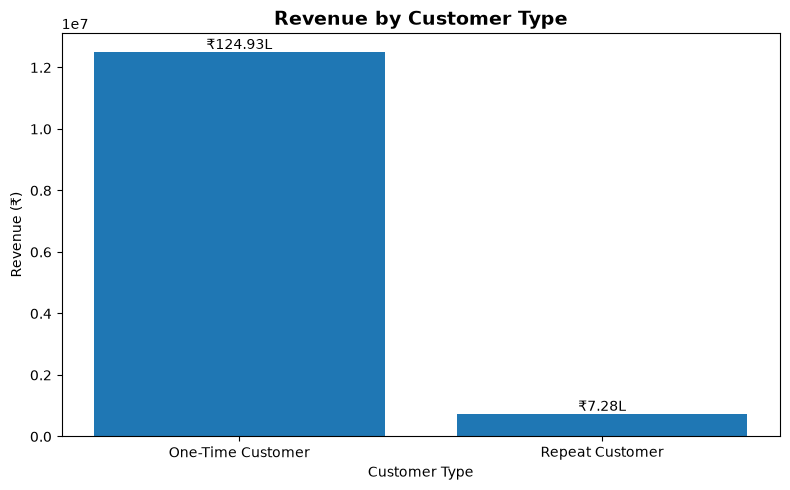

In [24]:
plt.figure(figsize=(8, 5))

bars = plt.bar(
    customer_type_chart["customer_type"],
    customer_type_chart["revenue"]
)

plt.title("Revenue by Customer Type", fontsize=14, fontweight="bold")
plt.xlabel("Customer Type")
plt.ylabel("Revenue (₹)")

# Add revenue labels
for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height,
        f"₹{height/100000:.2f}L",
        ha="center",
        va="bottom",
        fontsize=10
    )

plt.tight_layout()
plt.show()

In [25]:
# Customer revenue by state

customer_state = customer_orders.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

state_revenue = (
    customer_state
    .groupby("customer_state")
    .agg(
        customers=("customer_unique_id", "nunique"),
        orders=("order_id", "nunique"),
        revenue=("revenue", "sum")
    )
    .reset_index()
    .sort_values("revenue", ascending=False)
)

state_revenue.head(10)

,customer_state,customers,orders,revenue
25,SP,39156,40501,5067633.16
18,RJ,11917,12350,1759651.13
10,MG,11001,11354,1552481.83
22,RS,5168,5345,728897.47
17,PR,4769,4923,666063.51
23,SC,3449,3546,507012.13
4,BA,3158,3256,493584.14
6,DF,2019,2080,296498.41
8,GO,1895,1957,282836.70
7,ES,1928,1995,268643.45


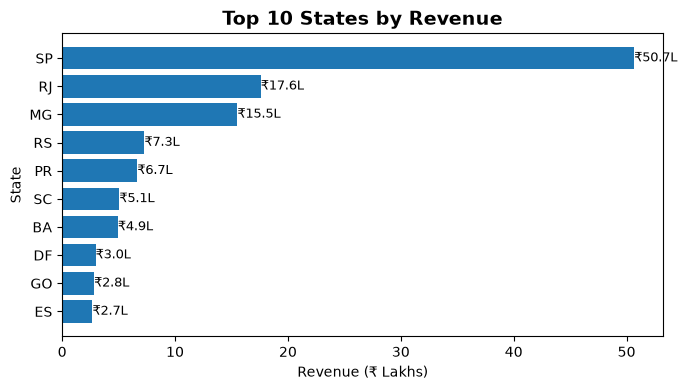

In [28]:
plt.figure(figsize=(7, 4))

top_states = state_revenue.head(10).sort_values("revenue")

bars = plt.barh(
    top_states["customer_state"],
    top_states["revenue"] / 100000
)

plt.title("Top 10 States by Revenue", fontsize=14, fontweight="bold")
plt.xlabel("Revenue (₹ Lakhs)")
plt.ylabel("State")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"₹{width:.1f}L",
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [29]:
# Product category performance

order_items_products = order_items.merge(
    products[["product_id", "product_category_name"]],
    on="product_id",
    how="left"
)

order_items_products = order_items_products.merge(
    category_translation,
    on="product_category_name",
    how="left"
)

category_revenue = (
    order_items_products
    .groupby("product_category_name_english")
    .agg(
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
    .reset_index()
    .sort_values("revenue", ascending=False)
)

category_revenue.head(15)

,product_category_name_english,items_sold,revenue
43,health_beauty,9670,1258681.34
70,watches_gifts,5991,1205005.68
7,bed_bath_table,11115,1036988.68
65,sports_leisure,8641,988048.97
15,computers_accessories,7827,911954.32
39,furniture_decor,8334,729762.49
20,cool_stuff,3796,635290.85
49,housewares,6964,632248.66
5,auto,4235,592720.11
42,garden_tools,4347,485256.46


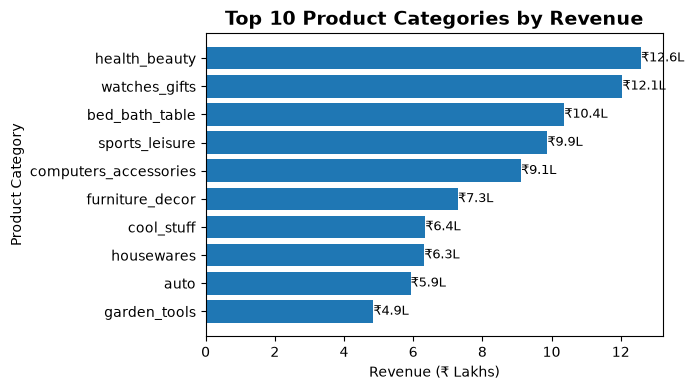

In [31]:
top_categories = category_revenue.head(10).sort_values("revenue")

plt.figure(figsize=(7, 4))

bars = plt.barh(
    top_categories["product_category_name_english"],
    top_categories["revenue"] / 100000
)

plt.title("Top 10 Product Categories by Revenue",
          fontsize=14, fontweight="bold")
plt.xlabel("Revenue (₹ Lakhs)")
plt.ylabel("Product Category")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"₹{width:.1f}L",
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()
plt.show()

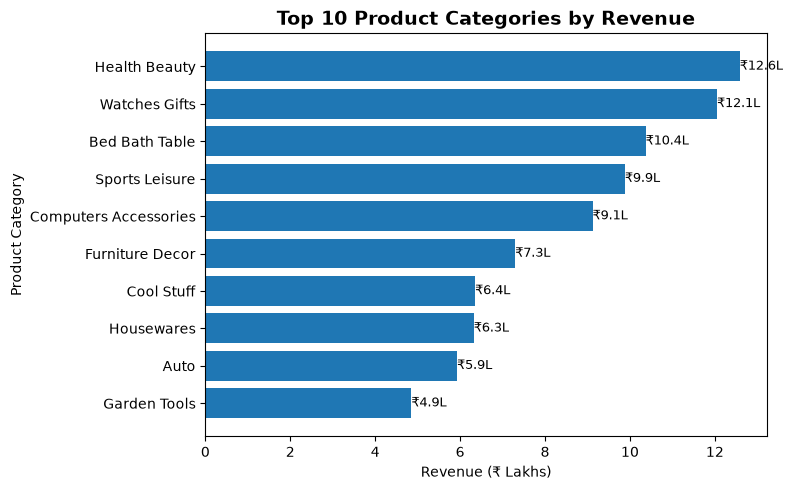

In [33]:
top_categories = category_revenue.head(10).sort_values("revenue").copy()

top_categories["category_label"] = (
    top_categories["product_category_name_english"]
    .str.replace("_", " ")
    .str.title()
)

plt.figure(figsize=(8, 5))

bars = plt.barh(
    top_categories["category_label"],
    top_categories["revenue"] / 100000
)

plt.title(
    "Top 10 Product Categories by Revenue",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Revenue (₹ Lakhs)")
plt.ylabel("Product Category")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"₹{width:.1f}L",
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [34]:
# Category-wise customer satisfaction

category_reviews = order_items_products.merge(
    reviews[["order_id", "review_score"]],
    on="order_id",
    how="inner"
)

category_satisfaction = (
    category_reviews
    .groupby("product_category_name_english")
    .agg(
        reviews=("review_score", "count"),
        avg_review_score=("review_score", "mean")
    )
    .reset_index()
)

category_satisfaction["negative_review_pct"] = (
    category_reviews
    .assign(negative=category_reviews["review_score"] <= 2)
    .groupby("product_category_name_english")["negative"]
    .mean()
    .values * 100
)

category_performance = category_revenue.merge(
    category_satisfaction,
    on="product_category_name_english",
    how="left"
)

category_performance = category_performance.sort_values(
    "revenue",
    ascending=False
)

category_performance.head(15)

,product_category_name_english,items_sold,revenue,reviews,avg_review_score,negative_review_pct
0,health_beauty,9670,1258681.34,9645,4.142768,13.696216
1,watches_gifts,5991,1205005.68,5950,4.019160,16.252101
2,bed_bath_table,11115,1036988.68,11137,3.895663,18.963814
3,sports_leisure,8641,988048.97,8640,4.107986,14.583333
4,computers_accessories,7827,911954.32,7849,3.930819,18.613836
5,furniture_decor,8334,729762.49,8331,3.903493,19.457448
6,cool_stuff,3796,635290.85,3772,4.146341,13.123012
7,housewares,6964,632248.66,6943,4.055019,15.641653
8,auto,4235,592720.11,4213,4.065512,15.262283
9,garden_tools,4347,485256.46,4329,4.042735,16.077616


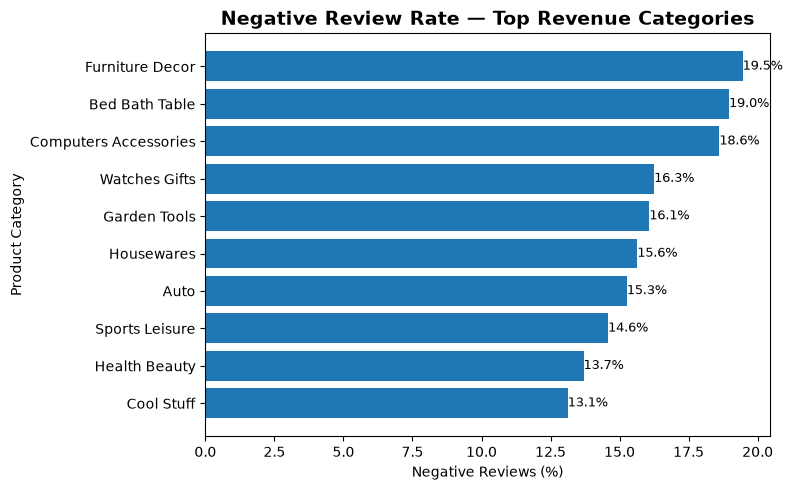

In [35]:
top_category_analysis = (
    category_performance
    .head(10)
    .sort_values("negative_review_pct")
    .copy()
)

top_category_analysis["category_label"] = (
    top_category_analysis["product_category_name_english"]
    .str.replace("_", " ")
    .str.title()
)

plt.figure(figsize=(8, 5))

bars = plt.barh(
    top_category_analysis["category_label"],
    top_category_analysis["negative_review_pct"]
)

plt.title(
    "Negative Review Rate — Top Revenue Categories",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Negative Reviews (%)")
plt.ylabel("Product Category")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.1f}%",
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [36]:
# Top products by revenue

product_revenue = (
    order_items_products
    .groupby(["product_id", "product_category_name_english"])
    .agg(
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum")
    )
    .reset_index()
    .sort_values("revenue", ascending=False)
)

product_revenue.head(15)

,product_id,product_category_name_english,items_sold,revenue
23641,bb50f2e236e5eea0100680137654686c,health_beauty,195,63885.00
13808,6cdd53843498f92890544667809f1595,health_beauty,156,54730.20
27102,d6160fb7873f184099d9bc95e30376af,computers,35,48899.34
26533,d1c427060a0f73f6b889a5c7c61f2ac4,computers_accessories,343,47214.51
19387,99a4788cb24856965c36a24e339b6058,bed_bath_table,488,43025.56
7902,3dd2a17168ec895c781a9191c1e95ad7,computers_accessories,274,41082.60
4901,25c38557cf793876c5abdd5931f922db,baby,38,38907.32
12125,5f504b3a1c75b73d6151be81eb05bdc9,cool_stuff,63,37733.90
10662,53b36df67ebb7c41585e8d54d6772e08,watches_gifts,323,37683.42
21716,aca2eb7d00ea1a7b8ebd4e68314663af,furniture_decor,527,37608.90


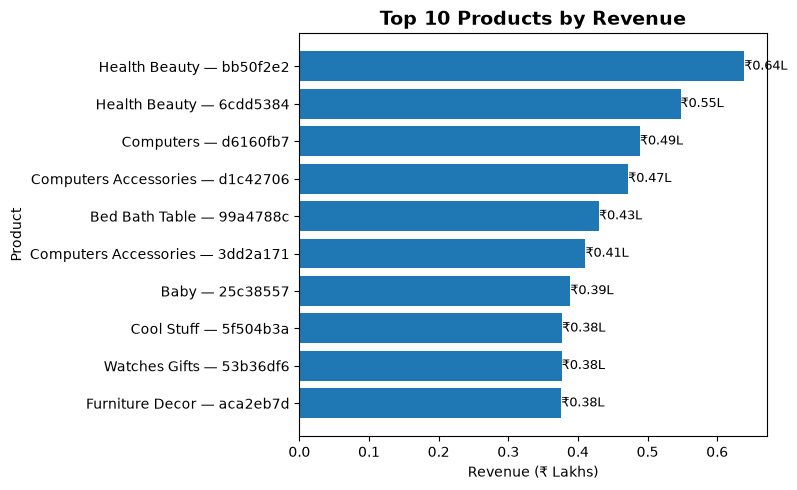

In [37]:
top_products = product_revenue.head(10).copy()

top_products["product_label"] = (
    top_products["product_category_name_english"]
    .str.replace("_", " ")
    .str.title()
    + " — "
    + top_products["product_id"].str[:8]
)

top_products = top_products.sort_values("revenue")

plt.figure(figsize=(8, 5))

bars = plt.barh(
    top_products["product_label"],
    top_products["revenue"] / 100000
)

plt.title(
    "Top 10 Products by Revenue",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Revenue (₹ Lakhs)")
plt.ylabel("Product")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"₹{width:.2f}L",
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [38]:
seller_revenue = (
    order_items
    .groupby("seller_id")
    .agg(
        items_sold=("order_item_id", "count"),
        revenue=("price", "sum"),
        freight_revenue=("freight_value", "sum"),
        orders=("order_id", "nunique")
    )
    .reset_index()
)

seller_revenue["avg_order_value"] = (
    seller_revenue["revenue"] / seller_revenue["orders"]
)

seller_revenue = seller_revenue.sort_values(
    "revenue",
    ascending=False
)

seller_revenue.head(10)

,seller_id,items_sold,revenue,freight_revenue,orders,avg_order_value
857,4869f7a5dfa277a7dca6462dcf3b52b2,1156,229472.63,20168.07,1132,202.714337
1013,53243585a1d6dc2643021fd1853d8905,410,222776.05,13080.63,358,622.279469
881,4a3ca9315b744ce9f8e9374361493884,1987,200472.92,35067.04,1806,111.003832
3024,fa1c13f2614d7b5c4749cbc52fecda94,586,194042.03,10042.70,585,331.695778
1535,7c67e1448b00f6e969d365cea6b010ab,1364,187923.89,51612.55,982,191.368523
1560,7e93a43ef30c4f03f38b393420bc753a,340,176431.87,6322.18,336,525.094851
2643,da8622b14eb17ae2831f4ac5b9dab84a,1551,160236.57,24955.75,1314,121.945639
1505,7a67c85e85bb2ce8582c35f2203ad736,1171,141745.53,20902.85,1160,122.194422
192,1025f0e2d44d7041d6cf58b6550e0bfa,1428,138968.55,33892.14,915,151.878197
1824,955fee9216a65b617aa5c0531780ce60,1499,135171.70,25430.98,1287,105.028516


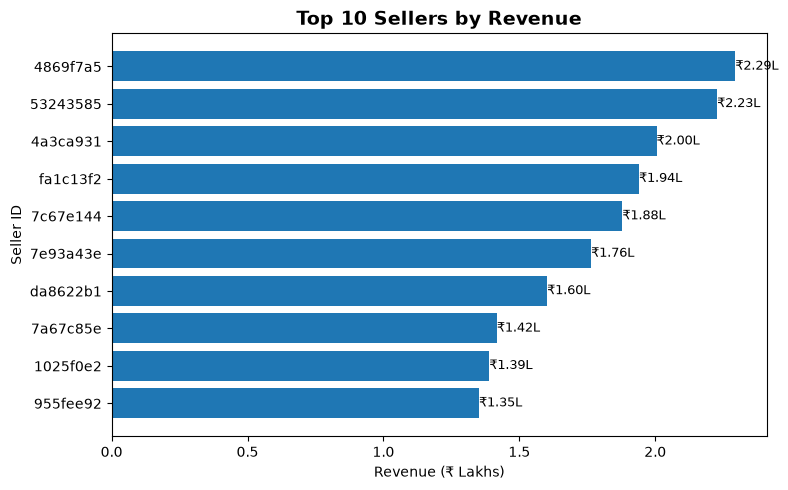

In [39]:
top_sellers = seller_revenue.head(10).copy()

top_sellers["seller_label"] = (
    top_sellers["seller_id"].str[:8]
)

top_sellers = top_sellers.sort_values("revenue")

plt.figure(figsize=(8, 5))

bars = plt.barh(
    top_sellers["seller_label"],
    top_sellers["revenue"] / 100000
)

plt.title(
    "Top 10 Sellers by Revenue",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Revenue (₹ Lakhs)")
plt.ylabel("Seller ID")

for bar in bars:
    width = bar.get_width()
    plt.text(
        width,
        bar.get_y() + bar.get_height() / 2,
        f"₹{width:.2f}L",
        va="center",
        ha="left",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [40]:
seller_reviews = (
    order_items
    .merge(
        reviews[["order_id", "review_score"]],
        on="order_id",
        how="inner"
    )
    .groupby("seller_id")
    .agg(
        reviews=("review_score", "count"),
        avg_review_score=("review_score", "mean")
    )
    .reset_index()
)

seller_performance = seller_revenue.merge(
    seller_reviews,
    on="seller_id",
    how="left"
)

seller_performance = seller_performance.sort_values(
    "revenue",
    ascending=False
)

seller_performance.head(10)

,seller_id,items_sold,revenue,freight_revenue,orders,avg_order_value,reviews,avg_review_score
0,4869f7a5dfa277a7dca6462dcf3b52b2,1156,229472.63,20168.07,1132,202.714337,1148.0,4.122822
1,53243585a1d6dc2643021fd1853d8905,410,222776.05,13080.63,358,622.279469,408.0,4.075980
2,4a3ca9315b744ce9f8e9374361493884,1987,200472.92,35067.04,1806,111.003832,1984.0,3.803931
3,fa1c13f2614d7b5c4749cbc52fecda94,586,194042.03,10042.70,585,331.695778,582.0,4.340206
4,7c67e1448b00f6e969d365cea6b010ab,1364,187923.89,51612.55,982,191.368523,1367.0,3.348208
5,7e93a43ef30c4f03f38b393420bc753a,340,176431.87,6322.18,336,525.094851,339.0,4.206490
6,da8622b14eb17ae2831f4ac5b9dab84a,1551,160236.57,24955.75,1314,121.945639,1568.0,4.071429
7,7a67c85e85bb2ce8582c35f2203ad736,1171,141745.53,20902.85,1160,122.194422,1166.0,4.234991
8,1025f0e2d44d7041d6cf58b6550e0bfa,1428,138968.55,33892.14,915,151.878197,1431.0,3.849755
9,955fee9216a65b617aa5c0531780ce60,1499,135171.70,25430.98,1287,105.028516,1489.0,4.051713


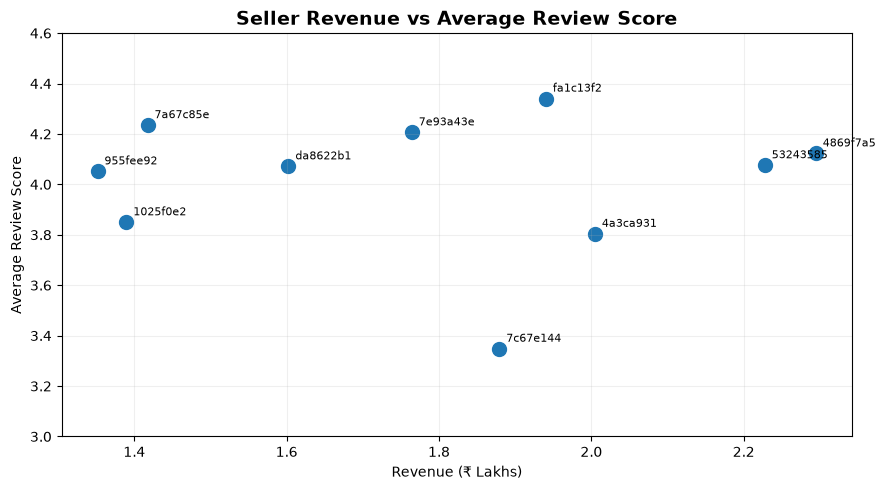

In [41]:
top_sellers_rating = seller_performance.head(10).copy()

top_sellers_rating["seller_label"] = (
    top_sellers_rating["seller_id"].str[:8]
)

plt.figure(figsize=(9, 5))

plt.scatter(
    top_sellers_rating["revenue"] / 100000,
    top_sellers_rating["avg_review_score"],
    s=100
)

for _, row in top_sellers_rating.iterrows():
    plt.annotate(
        row["seller_label"],
        (
            row["revenue"] / 100000,
            row["avg_review_score"]
        ),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

plt.title(
    "Seller Revenue vs Average Review Score",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Revenue (₹ Lakhs)")
plt.ylabel("Average Review Score")

plt.ylim(3, 4.6)
plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [42]:
# Delivery performance analysis

delivery_data = delivered_orders[
    [
        "order_id",
        "order_purchase_timestamp",
        "order_delivered_customer_date",
        "order_estimated_delivery_date"
    ]
].copy()

delivery_data["delivery_days"] = (
    delivery_data["order_delivered_customer_date"]
    - delivery_data["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

delivery_data["late_delivery"] = (
    delivery_data["order_delivered_customer_date"]
    > delivery_data["order_estimated_delivery_date"]
)

print("Average delivery time:",
      round(delivery_data["delivery_days"].mean(), 2), "days")

print("Median delivery time:",
      round(delivery_data["delivery_days"].median(), 2), "days")

print("Late deliveries:",
      delivery_data["late_delivery"].sum())

print("Late delivery rate:",
      round(delivery_data["late_delivery"].mean() * 100, 2), "%")

Average delivery time: 12.56 days
Median delivery time: 10.22 days
Late deliveries: 7826
Late delivery rate: 8.11 %


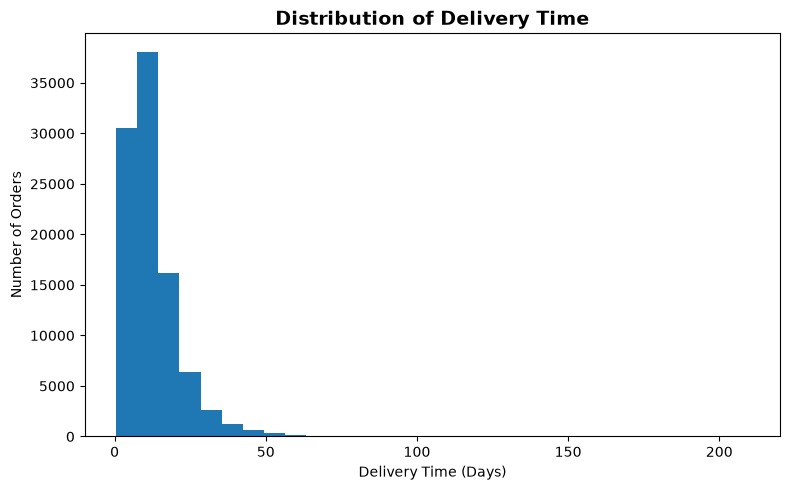

In [43]:
plt.figure(figsize=(8, 5))

plt.hist(
    delivery_data["delivery_days"],
    bins=30
)

plt.title(
    "Distribution of Delivery Time",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Delivery Time (Days)")
plt.ylabel("Number of Orders")

plt.tight_layout()
plt.show()

In [44]:

delivery_data["delivery_bucket"] = pd.cut(
    delivery_data["delivery_days"],
    bins=[0, 7, 14, 21, 30, float("inf")],
    labels=[
        "0–7 Days",
        "8–14 Days",
        "15–21 Days",
        "22–30 Days",
        "30+ Days"
    ]
)

delivery_buckets = (
    delivery_data
    .groupby("delivery_bucket", observed=False)
    .agg(
        orders=("order_id", "count"),
        late_orders=("late_delivery", "sum")
    )
    .reset_index()
)

delivery_buckets["percentage"] = (
    delivery_buckets["orders"]
    / delivery_buckets["orders"].sum() * 100
)

delivery_buckets

,delivery_bucket,orders,late_orders,percentage
0,0–7 Days,26046,228,26.999067
1,8–14 Days,40212,520,41.683425
2,15–21 Days,17713,853,18.361149
3,22–30 Days,7949,2516,8.239867
4,30+ Days,4550,3709,4.716492


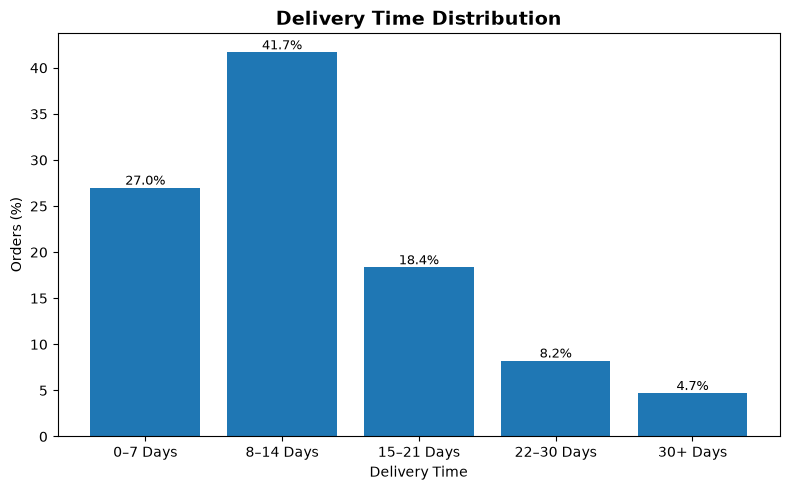

In [47]:


plt.figure(figsize=(8, 5))

bars = plt.bar(
    delivery_buckets["delivery_bucket"].astype(str),
    delivery_buckets["percentage"]
)

plt.title(
    "Delivery Time Distribution",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Delivery Time")
plt.ylabel("Orders (%)")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.1f}%",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.tight_layout()
plt.show()

In [48]:
delivery_data["purchase_month"] = (
    delivery_data["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly_delivery = (
    delivery_data
    .groupby("purchase_month")
    .agg(
        orders=("order_id", "count"),
        late_orders=("late_delivery", "sum")
    )
    .reset_index()
)

monthly_delivery["late_delivery_rate"] = (
    monthly_delivery["late_orders"]
    / monthly_delivery["orders"] * 100
)

monthly_delivery.head()

,purchase_month,orders,late_orders,late_delivery_rate
0,2016-09,1,1,100.000000
1,2016-10,265,3,1.132075
2,2016-12,1,0,0.000000
3,2017-01,750,23,3.066667
4,2017-02,1653,53,3.206292


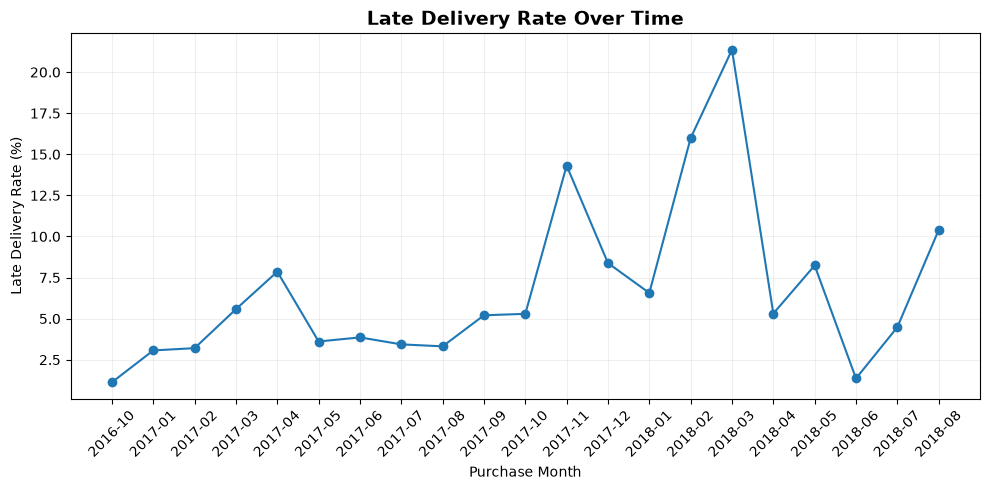

In [49]:
# Remove very low-volume months for a reliable trend
monthly_delivery_trend = monthly_delivery[
    monthly_delivery["orders"] >= 100
].copy()

plt.figure(figsize=(10, 5))

plt.plot(
    monthly_delivery_trend["purchase_month"],
    monthly_delivery_trend["late_delivery_rate"],
    marker="o"
)

plt.title(
    "Late Delivery Rate Over Time",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Purchase Month")
plt.ylabel("Late Delivery Rate (%)")

plt.xticks(rotation=45)

plt.grid(alpha=0.2)

plt.tight_layout()
plt.show()

In [50]:
# =========================
# FINAL KPI SUMMARY
# =========================

# Revenue from delivered orders
total_revenue = customer_orders["revenue"].sum()

# Delivered items
delivered_item_data = order_items.merge(
    delivered_orders[["order_id"]],
    on="order_id",
    how="inner"
)

items_sold = len(delivered_item_data)

# Average Order Value
avg_order_value = total_revenue / len(delivered_orders)

# Customers
unique_customers = customer_orders["customer_unique_id"].nunique()

# Repeat customers
repeat_customers = (
    customer_revenue_summary["customer_type"]
    .eq("Repeat Customer")
    .sum()
)

repeat_customer_pct = (
    repeat_customers / unique_customers * 100
)

# Delivery KPIs
avg_delivery_days = delivery_data["delivery_days"].mean()
median_delivery_days = delivery_data["delivery_days"].median()
late_orders = delivery_data["late_delivery"].sum()
late_delivery_pct = delivery_data["late_delivery"].mean() * 100

# Review KPIs
avg_review_score = reviews["review_score"].mean()
negative_reviews = (reviews["review_score"] <= 2).sum()
negative_review_pct = negative_reviews / len(reviews) * 100

kpi_summary = pd.DataFrame({
    "KPI": [
        "Delivered Orders",
        "Total Revenue",
        "Items Sold",
        "Average Order Value",
        "Unique Customers",
        "Repeat Customers",
        "Repeat Customer %",
        "Average Delivery Time",
        "Median Delivery Time",
        "Late Orders",
        "Late Delivery %",
        "Average Review Score",
        "Negative Reviews",
        "Negative Review %"
    ],
    "Value": [
        len(delivered_orders),
        total_revenue,
        items_sold,
        avg_order_value,
        unique_customers,
        repeat_customers,
        repeat_customer_pct,
        avg_delivery_days,
        median_delivery_days,
        late_orders,
        late_delivery_pct,
        avg_review_score,
        negative_reviews,
        negative_review_pct
    ]
})

kpi_summary

,KPI,Value
0,Delivered Orders,9.647800e+04
1,Total Revenue,1.322150e+07
2,Items Sold,1.101970e+05
3,Average Order Value,1.370416e+02
4,Unique Customers,9.335800e+04
5,Repeat Customers,2.801000e+03
6,Repeat Customer %,3.000278e+00
7,Average Delivery Time,1.255822e+01
8,Median Delivery Time,1.021748e+01
9,Late Orders,7.826000e+03


In [52]:
kpi_display = kpi_summary.copy()

kpi_display["Value"] = [
    f"{value:,.0f}" if i in [0, 2, 4, 5, 9, 12]
    else f"₹{value/100000:.2f}L" if i == 1
    else f"₹{value:,.2f}" if i == 3
    else f"{value:.2f}%" if i in [6, 10, 13]
    else f"{value:.2f} days" if i in [7, 8]
    else f"{value:.2f} / 5" if i == 11
    else f"{value:,.0f}"
    for i, value in enumerate(kpi_summary["Value"])
]

kpi_display

,KPI,Value
0,Delivered Orders,"96,478"
1,Total Revenue,₹132.21L
2,Items Sold,"110,197"
3,Average Order Value,₹137.04
4,Unique Customers,"93,358"
5,Repeat Customers,"2,801"
6,Repeat Customer %,3.00%
7,Average Delivery Time,12.56 days
8,Median Delivery Time,10.22 days
9,Late Orders,"7,826"


# Key Business Insights

## Customer Insights
- The customer base is highly concentrated in one-time buyers, with repeat customers representing only 3% of customers.
- Repeat customers generate a higher average revenue per customer than one-time customers.
- Increasing customer retention and repeat purchases represents a significant growth opportunity.

## Product & Category Insights
- Health & Beauty is the highest-revenue product category.
- Watches & Gifts and Bed Bath Table are also major revenue contributors.
- Furniture Decor, Bed Bath Table, and Computers Accessories have relatively high negative-review rates.
- High revenue does not always correspond to high customer satisfaction.

## Geographic Insights
- São Paulo (SP) is the dominant revenue-generating state.
- Rio de Janeiro (RJ) and Minas Gerais (MG) are the next-largest markets.
- Revenue is concentrated in a relatively small number of major states.

## Seller Insights
- A small group of sellers contributes significantly to marketplace revenue.
- High seller revenue does not always correspond to high customer ratings.
- Some high-revenue sellers have relatively low review scores and may require operational or service improvements.

## Delivery Insights
- Average delivery time is 12.56 days, while the median is 10.22 days.
- 8.11% of delivered orders were late.
- The largest delivery-time group is 8–14 days, representing approximately 41.7% of delivered orders.
- Orders taking more than 30 days represent only 4.7% of deliveries but account for a large share of late orders.
- Late-delivery rates fluctuate considerably across months, with notable spikes during 2017–2018.

# Business Recommendations

1. **Improve customer retention**  
   Develop personalized offers, loyalty incentives, and targeted campaigns to convert one-time buyers into repeat customers.

2. **Investigate high-revenue categories with poor satisfaction**  
   Prioritize Furniture Decor, Bed Bath Table, and Computers Accessories for product-quality, packaging, and service analysis.

3. **Monitor seller performance**  
   Identify high-revenue sellers with low ratings and investigate recurring customer complaints.

4. **Reduce delivery delays**  
   Investigate months and sellers associated with unusually high late-delivery rates.

5. **Focus geographic expansion**  
   Maintain strong operations in major markets such as SP, RJ, and MG while evaluating growth opportunities in lower-revenue states.


# Conclusion

This analysis provides an end-to-end view of e-commerce sales, customers, products, sellers, geography, and delivery performance.

The analysis shows strong revenue concentration across major product categories and states, while repeat-customer penetration remains low. Several high-revenue categories and sellers also show relatively high negative-review rates, indicating opportunities to improve customer satisfaction. Delivery performance is another important operational area, with 8.11% of delivered orders arriving late and significant monthly fluctuations in late-delivery rates.

Overall, the findings suggest that the strongest opportunities are customer retention, product and seller quality improvement, geographic growth, and delivery-performance optimization.